# Spatiotemporal Hotspot Analysis and Severity Prediction of Road Accidents
### using Apache Sedona and Spark MLlib

**Spatial Big Data · Lanka Priya (253305) · MSc Data Science and Geoinformatics, Digital University Kerala**

This notebook implements the project exactly as proposed in the project-idea presentation, using the
**UK Department for Transport STATS19 road collision data (2021–2025, 513,801 collisions)** as the
"national open data" source.

**Problem (slide 2).** Road accidents are analysed after the fact. Authorities lack a scalable way to see
*where*, *when* and *why* severe crashes cluster, and *which conditions make a crash severe*.

**Pipeline (slide 4):** `1 Clean → 2 Store → 3 Wrangle → 4 Model → 5 Deliver`

| Proposal item | Implemented in this notebook |
|---|---|
| Clean – coordinates, duplicates, missing values | §3 |
| Store – PostGIS storage, Sedona spatial partitioning | §4 (KDB-tree partitioning + R-tree index, GeoParquet, PostGIS) |
| Wrangle – spatial joins, indexing, hourly & seasonal features | §5 (Sedona point-in-polygon join, 5 km grid, H3 hexagons) |
| Model – RF or GBT severity classifier | §8 (Spark MLlib Random Forest, GBT, Logistic Regression baselines) |
| Model – K-Means or DBSCAN hotspots | §7 (Spark MLlib K-Means, Sedona DBSCAN, Getis-Ord Gi*) |
| Model – FP-Growth rules | §9 (Spark MLlib FP-Growth) |
| Spark vs Sedona | §10 (spatial-join benchmark) |
| Deliver – map dashboard for hotspots and risk | §11 (exports for the Streamlit dashboard `app.py`) |

**Research questions**
1. Where do collisions, and especially fatal and serious (KSI) collisions, concentrate in Great Britain, and are these concentrations statistically significant?
2. When do collisions happen (hour, day, month, season), and how has the pattern changed 2021–2025?
3. Which road, environmental and temporal conditions are associated with a collision being severe?
4. How well can collision severity be predicted from conditions recorded for the collision, and which areas have the highest predicted severity risk?

## 1. Environment and configuration

The notebook runs on any machine with Java 17, PySpark 3.5 and Apache Sedona 1.7 (tested on Linux/WSL2 and the
university DGX). All paths are relative to the project root, so the same notebook runs unchanged in both places.
Raw files are downloaded automatically if they are missing.

In [1]:
import os, sys, json, time, tempfile, warnings
from pathlib import Path
from itertools import chain

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
os.environ.setdefault("PYSPARK_DRIVER_PYTHON", sys.executable)
# Windows only: Spark needs Hadoop's winutils.exe/hadoop.dll (expected in C:\hadoop\bin) to write files
if os.name == "nt":
    os.environ.setdefault("HADOOP_HOME", r"C:\hadoop")
    os.environ["PATH"] = os.path.join(os.environ["HADOOP_HOME"], "bin") + os.pathsep + os.environ["PATH"]
    os.environ.setdefault("SPARK_LOCAL_DIRS", os.path.join(os.environ["HADOOP_HOME"], "tmp"))

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RAW = Path(os.environ.get("ROAD_RAW_DIR", ROOT / "data" / "raw"))
PROC = ROOT / "data" / "processed"
DASH = ROOT / "data" / "dashboard"
FIG = ROOT / "outputs" / "figures"
DOCS = ROOT / "documentation"
MODELS = ROOT / "models"
for p in (RAW, PROC, DASH, FIG, DOCS, MODELS):
    p.mkdir(parents=True, exist_ok=True)

COLLISIONS_CSV = RAW / "dft-road-casualty-statistics-collision-last-5-years.csv"
LAD_GEOJSON = RAW / "lad_boundaries_gb_bgc.geojson"
DATA_GUIDE = RAW / "stats19_data_guide_2025.xlsx"
SOURCES = {
    COLLISIONS_CSV: "https://data.dft.gov.uk/road-accidents-safety-data/dft-road-casualty-statistics-collision-last-5-years.csv",
    LAD_GEOJSON: ("https://services1.arcgis.com/ESMARspQHYMw9BZ9/arcgis/rest/services/"
                  "Local_Authority_Districts_December_2021_GB_BGC_2022/FeatureServer/0/query"
                  "?where=1%3D1&outFields=LAD21CD,LAD21NM&outSR=4326&f=geojson"),
    DATA_GUIDE: ("https://assets.publishing.service.gov.uk/media/6ab2a71d997a4b2950cced58/"
                 "dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx"),
}
for dest, url in SOURCES.items():
    if not dest.exists():
        import urllib.request
        print("Downloading", dest.name)
        urllib.request.urlretrieve(url, dest)
    print(f"{dest.name:60s} {dest.stat().st_size/1e6:8.1f} MB")

# Analysis parameters (all decisions in one place)
SEED = 42
GRID_M = 5_000            # 5 km x 5 km screening grid (British National Grid metres)
H3_RES = 7                # H3 resolution 7 ~ 5.2 km^2 hexagons
TEST_YEAR = 2025          # chronological hold-out year
COAST_TOL_M = 1_000       # points within 1 km of a district polygon are assigned to it
GI_BAND_M = GRID_M * 1.5  # Gi* neighbourhood: the 8 surrounding 5 km cells
DBSCAN_FATAL = dict(epsilon=1_000.0, min_pts=4)   # fatal-crash clusters
DBSCAN_KSI = dict(epsilon=150.0, min_pts=12)      # junction-scale KSI clusters
FP_MIN_SUPPORT, FP_MIN_CONFIDENCE = 0.002, 0.01

# Colour scheme shared with the dashboard and the presentation
NAVY, TEAL, ORANGE, CREAM = "#0f1b2d", "#2bb3a3", "#e0612a", "#f5f3ee"
SEV_COLORS = {"Fatal": "#7a0f2a", "Serious": ORANGE, "Slight": TEAL}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10})

def jdump(obj, path):
    json.dump(obj, open(path, "w"), indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")
    plt.show()

print("Project root:", ROOT)

dft-road-casualty-statistics-collision-last-5-years.csv          97.7 MB
lad_boundaries_gb_bgc.geojson                                    18.6 MB
stats19_data_guide_2025.xlsx                                      0.1 MB
Project root: C:\Users\LANKA PRIYA\Downloads\Road_Accident_Project\Final_Project


In [2]:
from pyspark import StorageLevel
from pyspark.sql import functions as F, Window
from sedona.spark import SedonaContext

PACKAGES = ",".join([
    "org.apache.sedona:sedona-spark-shaded-3.5_2.12:1.7.1",
    "org.datasyslab:geotools-wrapper:1.7.1-28.5",
    "graphframes:graphframes:0.8.3-spark3.5-s_2.12",   # needed by Sedona DBSCAN
    "org.postgresql:postgresql:42.7.4",                 # PostGIS JDBC writer
])
config = (SedonaContext.builder()
          .appName("RoadAccidentSpatiotemporal")
          .master(os.environ.get("SPARK_MASTER", "local[4]"))
          .config("spark.jars.packages", PACKAGES)
          .config("spark.jars.repositories", "https://repos.spark-packages.org")
          .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "3g"))
          .config("spark.sql.shuffle.partitions", "32")
          .config("spark.sql.session.timeZone", "UTC")
          .config("spark.sql.execution.arrow.pyspark.enabled", "true")
          .getOrCreate())
sedona = SedonaContext.create(config)
sedona.sparkContext.setLogLevel("ERROR")
sedona.sparkContext.setCheckpointDir(tempfile.mkdtemp(prefix="sedona_ckpt_"))

import pyspark, sedona as sedona_pkg, sklearn
print("Spark", sedona.version, "| Sedona", sedona_pkg.version, "| scikit-learn", sklearn.__version__,
      "| Python", sys.version.split()[0], "| master", sedona.sparkContext.master)

Spark 3.5.3 | Sedona 1.7.1 | scikit-learn 1.9.1 | Python 3.11.18 | master local[4]


## 2. Data and geospatial layers (slide 3)

| Proposal layer | Source used | Notes |
|---|---|---|
| Accident points (lat/lon) | STATS19 collisions 2021–2025 (DfT open data, OGL v3) | 513,801 police-reported injury collisions |
| Administrative boundaries | ONS Local Authority Districts, Dec 2021, GB, generalised 20 m (OGL v3) | 363 districts; also defines the Great Britain study area |
| H3 or grid cells | 5 km British National Grid squares **and** H3 resolution-7 hexagons | both generated with Sedona |
| Severity, date/time/season | STATS19 fields | Fatal / Serious / Slight |
| Weather, visibility | STATS19 `weather_conditions`, `light_conditions`, `road_surface_conditions` | recorded by police at the scene |
| Junction, signal, crossing flags | STATS19 `junction_detail`, `junction_control`, `pedestrian_crossing` | |
| Traffic and road class | STATS19 `first_road_class`, `road_type`, `speed_limit`, `trunk_road_flag` | |

STATS19 already records road class, road type, speed limit, junction and weather for every collision, so these
attributes come from the collision record itself rather than from separate OpenStreetMap or weather-archive joins.
STATS19 has no traffic-volume exposure, so collision counts describe *where crashes happen*, not *risk per vehicle-km*.

In [3]:
raw = (sedona.read.option("header", True).option("inferSchema", True)
       .csv(str(COLLISIONS_CSV)))
n_raw = raw.count()
print(f"Raw collision records: {n_raw:,}   columns: {len(raw.columns)}")
raw.select("collision_index", "collision_year", "date", "time", "longitude", "latitude",
           "collision_severity", "weather_conditions", "road_type", "speed_limit").show(5, truncate=False)

Raw collision records: 513,801   columns: 44


+---------------+--------------+----------+-------------------+---------+--------+------------------+------------------+---------+-----------+
|collision_index|collision_year|date      |time               |longitude|latitude|collision_severity|weather_conditions|road_type|speed_limit|
+---------------+--------------+----------+-------------------+---------+--------+------------------+------------------+---------+-----------+
|202417H105824  |2024          |03/10/2024|2026-11-07 16:06:00|-1.247   |54.6984 |2                 |1                 |6        |30         |
|202517M115025  |2025          |29/11/2025|2026-11-07 16:34:00|-1.19147 |54.56387|2                 |1                 |6        |30         |
|202517L306225  |2025          |01/06/2025|2026-11-07 22:07:00|-1.0839  |54.606  |3                 |1                 |6        |30         |
|202417S104724  |2024          |20/04/2024|2026-11-07 14:40:00|-1.37599 |54.55157|3                 |1                 |3        |60         |

### 2.1 Code labels from the official DfT data guide
STATS19 stores categories as integer codes. The 2025 data guide is used to translate them into labels.
Missing (`-1`) and "unknown" codes are mapped to `Unknown`.

In [4]:
guide = pd.read_excel(DATA_GUIDE, sheet_name="2024_code_list")
guide.columns = [str(c).strip().lower() for c in guide.columns]
guide = guide[guide["table"].astype(str).str.lower().str.contains("collision")]

LABEL_FIELDS = ["collision_severity", "day_of_week", "first_road_class", "road_type", "junction_detail",
                "junction_control", "pedestrian_crossing", "light_conditions", "weather_conditions",
                "road_surface_conditions", "carriageway_hazards", "urban_or_rural_area", "trunk_road_flag",
                "police_force"]
SHORT = {  # shorter labels for charts and the dashboard
    ("junction_detail", 0): "Not at junction", ("junction_detail", 13): "T or staggered junction",
    ("junction_detail", 17): "More than four arms", ("junction_detail", 18): "Private drive or entrance",
    ("junction_control", 0): "Not at junction", ("junction_control", 4): "Give way or uncontrolled",
    ("pedestrian_crossing", 0): "No crossing within 50 m",
    ("pedestrian_crossing", 11): "School crossing patrol", ("pedestrian_crossing", 12): "Other authorised person",
    ("pedestrian_crossing", 14): "Pedestrian light crossing", ("pedestrian_crossing", 15): "Pedestrian phase at signal",
    ("pedestrian_crossing", 17): "Central refuge",
    ("carriageway_hazards", 12): "Defective signs or markings", ("carriageway_hazards", 16): "Dislodged vehicle load",
    ("carriageway_hazards", 18): "Previous collision", ("carriageway_hazards", 19): "Pedestrian in carriageway",
    ("carriageway_hazards", 20): "Animal in carriageway", ("carriageway_hazards", 21): "Poor road surface",
    ("road_surface_conditions", 5): "Flood over 3 cm",
    ("trunk_road_flag", 1): "Trunk road", ("trunk_road_flag", 2): "Non-trunk",
    ("weather_conditions", 1): "Fine", ("weather_conditions", 2): "Raining",
    ("weather_conditions", 3): "Snowing", ("weather_conditions", 4): "Fine + high winds",
    ("weather_conditions", 5): "Raining + high winds", ("weather_conditions", 6): "Snowing + high winds",
}

def build_labels(field):
    sub = guide[guide["field name"].astype(str).str.strip() == field]
    out = {}
    for code, label in zip(sub["code/format"], sub["label"]):
        try:
            code = int(code)
        except (TypeError, ValueError):
            continue
        lab = "None" if pd.isna(label) else str(label).strip()
        if "missing" in lab.lower() or "unknown" in lab.lower():
            lab = "Unknown"
        out[code] = SHORT.get((field, code), lab)
    return out

LABELS = {f: build_labels(f) for f in LABEL_FIELDS}
pd.DataFrame({"field": list(LABELS), "codes": [len(v) for v in LABELS.values()],
              "example labels": [", ".join(list(dict.fromkeys(v.values()))[:4]) for v in LABELS.values()]})

,field,codes,example labels
0,collision_severity,3,"Fatal, Serious, Slight"
1,day_of_week,7,"Sunday, Monday, Tuesday, Wednesday"
2,first_road_class,7,"Motorway, A(M), A, B"
3,road_type,8,"Roundabout, One way street, Dual carriageway, ..."
4,junction_detail,8,"Not at junction, T or staggered junction, Cros..."
5,junction_control,7,"Not at junction, Authorised person, Auto traff..."
6,pedestrian_crossing,10,"No crossing within 50 m, School crossing patro..."
7,light_conditions,6,"Daylight, Darkness - lights lit, Darkness - li..."
8,weather_conditions,10,"Fine, Raining, Snowing, Fine + high winds"
9,road_surface_conditions,9,"Dry, Wet or damp, Snow, Frost or ice"


In [5]:
def label_col(field):
    mapping = F.create_map([F.lit(x) for x in chain(*LABELS[field].items())])
    return F.coalesce(mapping[F.col(field)], F.lit("Unknown"))

lad_gdf = (gpd.read_file(LAD_GEOJSON)[["LAD21CD", "LAD21NM", "geometry"]]
           .rename(columns={"LAD21CD": "lad_code", "LAD21NM": "lad_name"}))
lad_gdf["geometry"] = lad_gdf.geometry.make_valid()
lad_sdf = (sedona.createDataFrame(pd.DataFrame({"lad_code": lad_gdf.lad_code, "lad_name": lad_gdf.lad_name,
                                                "wkt": lad_gdf.geometry.to_wkt()}))
           .selectExpr("lad_code", "lad_name",
                       "ST_Transform(ST_GeomFromWKT(wkt), 'EPSG:4326', 'EPSG:27700') AS lad_geom")
           .persist(StorageLevel.MEMORY_AND_DISK))
print(f"Local authority districts: {lad_sdf.count()}  (England, Scotland, Wales)")
lad_sdf.selectExpr("lad_code", "lad_name", "ST_GeometryType(lad_geom) AS type",
                   "round(ST_Area(lad_geom)/1e6, 1) AS area_km2").show(5)

Local authority districts: 363  (England, Scotland, Wales)


+---------+--------------------+---------------+--------+
| lad_code|            lad_name|           type|area_km2|
+---------+--------------------+---------------+--------+
|E06000001|          Hartlepool|ST_MultiPolygon|    93.8|
|E06000002|       Middlesbrough|ST_MultiPolygon|    53.9|
|E06000003|Redcar and Cleveland|ST_MultiPolygon|   245.1|
|E06000004|    Stockton-on-Tees|ST_MultiPolygon|   204.9|
|E06000005|          Darlington|     ST_Polygon|   197.5|
+---------+--------------------+---------------+--------+
only showing top 5 rows



## 3. Step 1 – Clean: coordinates, duplicates, missing values
Checks performed:
* **Duplicates:** repeated `collision_index` values.
* **Coordinates:** missing longitude/latitude and points outside the Great Britain bounding box.
* **Date/time:** unparseable dates or times.
* **Missing values:** share of `-1` (data missing or out of range) for each analysis field.

In [6]:
INT_COLS = ["collision_year", "collision_severity", "day_of_week", "police_force", "number_of_vehicles",
            "number_of_casualties", "first_road_class", "road_type", "speed_limit", "junction_detail",
            "junction_control", "pedestrian_crossing", "light_conditions", "weather_conditions",
            "road_surface_conditions", "carriageway_hazards", "urban_or_rural_area", "trunk_road_flag",
            "special_conditions_at_site", "location_easting_osgr", "location_northing_osgr"]
df = raw
for c in INT_COLS:
    df = df.withColumn(c, F.col(c).cast("int"))
df = (df.withColumn("longitude", F.col("longitude").cast("double"))
        .withColumn("latitude", F.col("latitude").cast("double"))
        .withColumn("collision_date", F.to_date("date", "dd/MM/yyyy"))
        # inferSchema may read "16:06" as a timestamp (today's date + time), so take the HH of the first HH:MM
        .withColumn("hour", F.regexp_extract(F.col("time").cast("string"), r"(\d{1,2}):\d{2}", 1).cast("int")))
n_hours = df.select("hour").distinct().count()
assert n_hours == 24, f"expected 24 distinct hours, found {n_hours}"

quality = {"raw_records": n_raw}
quality["duplicate_collision_index"] = n_raw - df.select("collision_index").distinct().count()
df = df.dropDuplicates(["collision_index"])

LON_MIN, LAT_MIN, LON_MAX, LAT_MAX = -8.7, 49.8, 1.8, 60.9
has_xy = F.col("longitude").isNotNull() & F.col("latitude").isNotNull()
in_bbox = F.col("longitude").between(LON_MIN, LON_MAX) & F.col("latitude").between(LAT_MIN, LAT_MAX)
quality["missing_coordinates"] = df.filter(~has_xy).count()
quality["outside_gb_bounding_box"] = df.filter(has_xy & ~in_bbox).count()
quality["invalid_date"] = df.filter(F.col("collision_date").isNull()).count()
quality["invalid_time"] = df.filter(F.col("hour").isNull() | ~F.col("hour").between(0, 23)).count()

clean = df.filter(has_xy & in_bbox & F.col("collision_date").isNotNull())
quality["clean_records"] = clean.count()
pd.Series(quality, name="records").to_frame()

,records
raw_records,513801
duplicate_collision_index,0
missing_coordinates,53
outside_gb_bounding_box,0
invalid_date,0
invalid_time,0
clean_records,513748


In [7]:
CHECK_FIELDS = ["first_road_class", "road_type", "speed_limit", "junction_detail", "junction_control",
                "pedestrian_crossing", "light_conditions", "weather_conditions", "road_surface_conditions",
                "carriageway_hazards", "urban_or_rural_area", "trunk_road_flag", "special_conditions_at_site"]
miss = clean.select([F.round(100 * F.avg(F.when(F.col(c).isNull() | (F.col(c) == -1), 1).otherwise(0)), 2).alias(c)
                     for c in CHECK_FIELDS]).toPandas().T.rename(columns={0: "missing_%"})
miss_by_year = (clean.groupBy("collision_year")
                .agg(*[F.round(100 * F.avg(F.when(F.col(c) == -1, 1).otherwise(0)), 1).alias(c)
                       for c in ["special_conditions_at_site", "junction_detail", "pedestrian_crossing"]])
                .orderBy("collision_year").toPandas())
quality["missing_pct"] = miss["missing_%"].to_dict()
display(miss.sort_values("missing_%", ascending=False))
display(miss_by_year)

,missing_%
junction_control,42.41
special_conditions_at_site,29.46
trunk_road_flag,7.07
junction_detail,3.89
pedestrian_crossing,2.19
carriageway_hazards,1.93
road_surface_conditions,0.69
light_conditions,0.01
first_road_class,0.00
road_type,0.00


,collision_year,special_conditions_at_site,junction_detail,pedestrian_crossing
0,2021,0.3,2.0,0.2
1,2022,0.7,1.7,0.6
2,2023,3.0,2.3,2.7
3,2024,58.8,6.9,1.0
4,2025,86.5,6.6,6.4


**Cleaning decisions**
* No duplicate collision IDs were found. 53 records have no coordinates and are excluded from spatial analysis.
* Missing codes (`-1`) are kept as their own `Unknown` category rather than imputed: the absence of information is
  itself informative, and imputing categorical scene conditions would invent data.
* `special_conditions_at_site` is **mostly missing in 2024 and almost entirely missing in 2025** (DfT changed the
  collection form). It is excluded from modelling, because the 2025 test set would otherwise differ systematically
  from training data. The other fields are coded consistently across 2021–2025.

In [8]:
jdump(quality, DOCS / "data_quality_summary.json")

## 4. Step 2 – Store: Sedona geometries, spatial partitioning, GeoParquet and PostGIS
### 4.1 Geometry construction
Each collision becomes a Sedona point in WGS84 (`EPSG:4326`, for web maps) and in British National Grid
(`EPSG:27700`, metres, for distances, grids and clustering).

In [9]:
clean.createOrReplaceTempView("clean")
points = sedona.sql("""
    SELECT *,
           ST_Point(longitude, latitude) AS geom_wgs84,
           ST_Transform(ST_Point(longitude, latitude), 'EPSG:4326', 'EPSG:27700') AS geom_bng
    FROM clean
""")
# Validation: Sedona's projection should agree with the OS grid references recorded by the police
points.selectExpr("round(avg(abs(ST_X(geom_bng) - location_easting_osgr)), 2) AS mean_abs_diff_easting_m",
                  "round(avg(abs(ST_Y(geom_bng) - location_northing_osgr)), 2) AS mean_abs_diff_northing_m").show()

+-----------------------+------------------------+
|mean_abs_diff_easting_m|mean_abs_diff_northing_m|
+-----------------------+------------------------+
|                   0.28|                    0.39|
+-----------------------+------------------------+



### 4.2 Sedona spatial partitioning (KDB-tree) and R-tree index
Spark's default partitioning is by file position, so nearby collisions end up scattered across partitions.
Sedona's **KDB-tree** partitioner splits space so that each partition holds a similar number of collisions.
Spatial joins and neighbourhood queries then only compare objects in overlapping partitions. An **R-tree index**
is built inside each partition.

KDB-tree partitions: 24 | collisions per partition: min 15,230, median 20,099, max 31,841


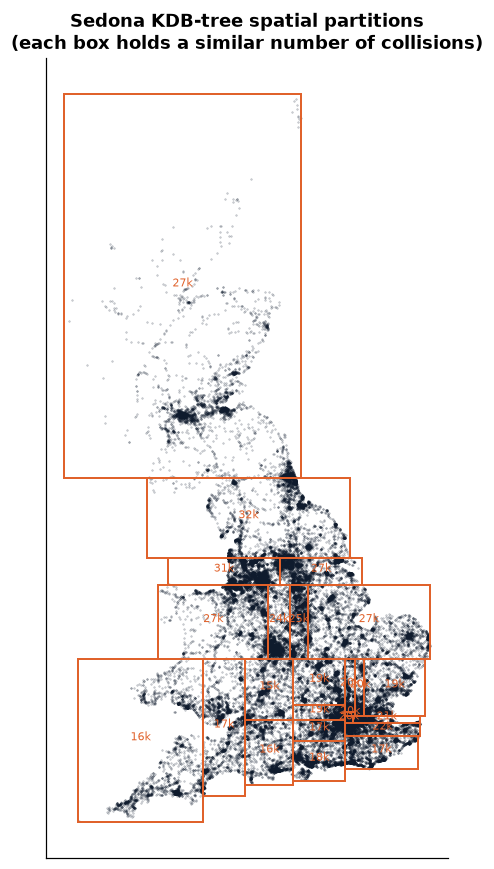

In [10]:
from sedona.utils.structured_adapter import StructuredAdapter
from sedona.core.enums import GridType, IndexType

spatial_rdd = StructuredAdapter.toSpatialRdd(points.select("collision_index", "geom_bng"), "geom_bng")
spatial_rdd.analyze()
spatial_rdd.spatialPartitioning(GridType.KDBTREE, 16)
spatial_rdd.buildIndex(IndexType.RTREE, True)
partitioned = StructuredAdapter.toSpatialPartitionedDf(spatial_rdd, sedona)

part_stats = (partitioned.groupBy(F.spark_partition_id().alias("partition"))
              .agg(F.count("*").alias("collisions"), F.expr("ST_AsText(ST_Envelope_Aggr(geom_bng))").alias("envelope"))
              .orderBy("partition").toPandas())
print(f"KDB-tree partitions: {len(part_stats)} | collisions per partition: "
      f"min {part_stats.collisions.min():,}, median {int(part_stats.collisions.median()):,}, max {part_stats.collisions.max():,}")

from shapely import wkt as shp_wkt
sample_xy = points.sample(0.15, seed=SEED).selectExpr("ST_X(geom_bng) x", "ST_Y(geom_bng) y").toPandas()
fig, ax = plt.subplots(figsize=(6.5, 8))
ax.scatter(sample_xy.x, sample_xy.y, s=0.15, c=NAVY, alpha=0.35, rasterized=True)
for _, r in part_stats.iterrows():
    g = shp_wkt.loads(r.envelope)
    ax.add_patch(mpatches.Polygon(np.array(g.exterior.coords), fill=False, ec=ORANGE, lw=1.3))
    ax.text(g.centroid.x, g.centroid.y, f"{r.collisions/1000:.0f}k", fontsize=7, color=ORANGE, ha="center")
ax.set_title("Sedona KDB-tree spatial partitions\n(each box holds a similar number of collisions)")
ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
savefig("store_kdbtree_partitions")

### 4.3 GeoParquet storage
The cleaned point layer is written as **GeoParquet**, partitioned by year. GeoParquet is the columnar spatial
format used in the rest of the pipeline.

In [11]:
STORE_PATH = PROC / "collisions_clean.geoparquet"
(points.drop("date", "time")
       .write.mode("overwrite").partitionBy("collision_year").format("geoparquet").save(str(STORE_PATH)))
stored = sedona.read.format("geoparquet").load(str(STORE_PATH))
n_points = stored.count()
print(f"GeoParquet records: {n_points:,}")
stored.groupBy("collision_year").count().orderBy("collision_year").show()

GeoParquet records: 513,748


+--------------+------+
|collision_year| count|
+--------------+------+
|          2021|101070|
|          2022|105982|
|          2023|104246|
|          2024|100927|
|          2025|101523|
+--------------+------+



### 4.4 PostGIS storage
As proposed, the point layer and district boundaries are loaded into **PostGIS** with Spark's JDBC writer. A GiST
spatial index is built and a spatial SQL query runs inside the database. Set `POSTGIS_URL` to point at your server
(the default is a local Docker container: `docker run -d --name road_postgis -e POSTGRES_PASSWORD=road
-e POSTGRES_DB=roads -p 55432:5432 postgis/postgis:16-3.4`). If no server is reachable, this step is skipped and
the rest of the pipeline continues from GeoParquet.

In [12]:
POSTGIS_URL = os.environ.get("POSTGIS_URL", "jdbc:postgresql://localhost:55432/roads")
PG_PROPS = {"user": os.environ.get("POSTGIS_USER", "postgres"),
            "password": os.environ.get("POSTGIS_PASSWORD", "road"), "driver": "org.postgresql.Driver"}
postgis_result = {"status": "skipped"}
try:
    import psycopg2
    host_port_db = POSTGIS_URL.split("//")[1]
    host, rest = host_port_db.split(":"); port, dbname = rest.split("/")
    conn = psycopg2.connect(host=host, port=int(port), dbname=dbname,
                            user=PG_PROPS["user"], password=PG_PROPS["password"], connect_timeout=5)
    conn.autocommit = True
    cur = conn.cursor()
    cur.execute("CREATE EXTENSION IF NOT EXISTS postgis;")

    t0 = time.time()
    (stored.selectExpr("collision_index", "collision_year", "collision_severity", "ST_AsBinary(geom_bng) AS wkb")
           .repartition(8).write.mode("overwrite").jdbc(POSTGIS_URL, "collisions_stage", properties=PG_PROPS))
    lad_sdf.selectExpr("lad_code", "lad_name", "ST_AsBinary(lad_geom) AS wkb") \
           .write.mode("overwrite").jdbc(POSTGIS_URL, "lad_stage", properties=PG_PROPS)
    cur.execute("""
        DROP TABLE IF EXISTS collisions; DROP TABLE IF EXISTS lad;
        CREATE TABLE collisions AS SELECT collision_index, collision_year, collision_severity,
               ST_SetSRID(ST_GeomFromWKB(wkb), 27700)::geometry(Point, 27700) AS geom FROM collisions_stage;
        CREATE TABLE lad AS SELECT lad_code, lad_name, ST_SetSRID(ST_GeomFromWKB(wkb), 27700) AS geom FROM lad_stage;
        DROP TABLE collisions_stage; DROP TABLE lad_stage;
        CREATE INDEX collisions_gix ON collisions USING GIST (geom);
        CREATE INDEX lad_gix ON lad USING GIST (geom);
        ANALYZE collisions; ANALYZE lad;
    """)
    load_s = time.time() - t0
    # Spatial SQL in PostGIS: fatal & serious collisions within 1 km of Westminster Bridge
    cur.execute("""
        SELECT collision_severity, count(*) FROM collisions
        WHERE ST_DWithin(geom, ST_Transform(ST_SetSRID(ST_Point(-0.1218, 51.5008), 4326), 27700), 1000)
        GROUP BY collision_severity ORDER BY collision_severity;""")
    near = cur.fetchall()
    cur.execute("SELECT count(*), pg_size_pretty(pg_total_relation_size('collisions')) FROM collisions;")
    n_pg, size_pg = cur.fetchone()
    cur.execute("SELECT PostGIS_Version();"); pg_ver = cur.fetchone()[0]
    postgis_result = {"status": "loaded", "rows": n_pg, "table_size": size_pg, "load_seconds": round(load_s, 1),
                      "postgis_version": pg_ver,
                      "within_1km_westminster_by_severity": {LABELS["collision_severity"][s]: c for s, c in near}}
    conn.close()
except Exception as e:
    postgis_result["reason"] = f"{type(e).__name__}: {str(e)[:200]}"
postgis_result

{'status': 'skipped',
 'reason': 'OperationalError: connection to server at "localhost" (::1), port 55432 failed: Connection refused (0x0000274D/10061)\n\tIs the server running on that host and accepting TCP/IP connections?\nconnection to server at "local'}

## 5. Step 3 – Wrangle: spatial joins, indexing and temporal features
### 5.1 Sedona spatial join – collisions → local authority districts
`ST_Contains` point-in-polygon join with the district polygons broadcast to every executor. The union of the
363 districts is Great Britain, so this join is also the **study-area filter**. Points just offshore (generalised
coastline, piers, estuary bridges) are assigned to the nearest district if it lies within 1 km (`ST_DWithin`
distance join). Anything further away is outside GB.

In [13]:
stored.createOrReplaceTempView("pts")
lad_sdf.createOrReplaceTempView("lad")
t0 = time.time()
contained = sedona.sql("""
    SELECT /*+ BROADCAST(l) */ p.collision_index, l.lad_code, l.lad_name
    FROM pts p JOIN lad l ON ST_Contains(l.lad_geom, p.geom_bng)
""").dropDuplicates(["collision_index"]).persist(StorageLevel.MEMORY_AND_DISK)
n_contained = contained.count()
unmatched = stored.join(contained, "collision_index", "left_anti")
unmatched.createOrReplaceTempView("unm")
nearest = sedona.sql(f"""
    SELECT /*+ BROADCAST(l) */ u.collision_index, l.lad_code, l.lad_name,
           ST_Distance(l.lad_geom, u.geom_bng) AS dist_m
    FROM unm u JOIN lad l ON ST_DWithin(l.lad_geom, u.geom_bng, {COAST_TOL_M})
""")
nearest = (nearest.withColumn("rk", F.row_number().over(Window.partitionBy("collision_index").orderBy("dist_m")))
           .filter("rk = 1").drop("rk", "dist_m"))
lad_assign = (contained.withColumn("lad_match", F.lit("inside polygon"))
              .unionByName(nearest.withColumn("lad_match", F.lit("nearest within 1 km"))))
join_counts = lad_assign.groupBy("lad_match").count().toPandas()
join_s = time.time() - t0
n_gb = int(join_counts["count"].sum())
quality.update({"inside_district_polygon": n_contained, "assigned_nearest_within_1km": n_gb - n_contained,
                "outside_great_britain": n_points - n_gb, "study_records": n_gb})
print(f"Spatial join finished in {join_s:.1f} s")
print(f"Inside a district polygon: {n_contained:,} | nearest district within 1 km: {n_gb - n_contained:,} | "
      f"outside GB (excluded): {n_points - n_gb:,} | study records: {n_gb:,}")

Spatial join finished in 9.5 s
Inside a district polygon: 513,249 | nearest district within 1 km: 496 | outside GB (excluded): 3 | study records: 513,745


### 5.2 Temporal, spatial-index and label features
* **Temporal:** hour, month, season, weekend flag and time band (night, morning peak, daytime, evening peak, late evening).
* **Spatial indexing:** a 5 km British National Grid cell id and an **H3 resolution-7 hexagon** id (Sedona `ST_H3CellIDs`).
* **Labels:** readable category labels from the DfT data guide.
* **Target:** `ksi` = killed or seriously injured (Fatal or Serious).

In [14]:
time_band = (F.when(F.col("hour").between(0, 5), "Night (00–05)")
             .when(F.col("hour").between(6, 9), "Morning peak (06–09)")
             .when(F.col("hour").between(10, 15), "Daytime (10–15)")
             .when(F.col("hour").between(16, 19), "Evening peak (16–19)")
             .otherwise("Late evening (20–23)"))
season = (F.when(F.col("month").isin(12, 1, 2), "Winter").when(F.col("month").isin(3, 4, 5), "Spring")
          .when(F.col("month").isin(6, 7, 8), "Summer").otherwise("Autumn"))

gb = (stored.join(lad_assign, "collision_index", "inner")
      .withColumn("month", F.month("collision_date"))
      .withColumn("season", season)
      .withColumn("time_band", time_band)
      .withColumn("is_weekend", F.col("day_of_week").isin(1, 7).cast("int"))
      .withColumn("ksi", (F.col("collision_severity") <= 2).cast("int"))
      .withColumn("easting", F.expr("ST_X(geom_bng)"))
      .withColumn("northing", F.expr("ST_Y(geom_bng)"))
      .withColumn("grid_x", F.floor(F.col("easting") / GRID_M).cast("int"))
      .withColumn("grid_y", F.floor(F.col("northing") / GRID_M).cast("int"))
      .withColumn("grid_id", F.concat_ws("_", "grid_x", "grid_y"))
      .withColumn("h3_cell", F.lower(F.hex(F.expr(f"ST_H3CellIDs(geom_wgs84, {H3_RES}, false)[0]")))))
for f in LABEL_FIELDS:
    gb = gb.withColumn(f + "_label", label_col(f))
gb = gb.withColumnRenamed("collision_severity_label", "severity")

WRANGLED_PATH = PROC / "collisions_wrangled.geoparquet"
gb.write.mode("overwrite").format("geoparquet").save(str(WRANGLED_PATH))
gb = sedona.read.format("geoparquet").load(str(WRANGLED_PATH)).persist(StorageLevel.MEMORY_AND_DISK)
print(f"Wrangled records: {gb.count():,} | columns: {len(gb.columns)}")
gb.select("collision_index", "severity", "collision_date", "hour", "season", "time_band", "lad_name",
          "grid_id", "h3_cell", "weather_conditions_label", "light_conditions_label").show(5, truncate=False)

Wrangled records: 513,745 | columns: 74
+---------------+--------+--------------+----+------+--------------------+----------------------+-------+---------------+------------------------+----------------------+
|collision_index|severity|collision_date|hour|season|time_band           |lad_name              |grid_id|h3_cell        |weather_conditions_label|light_conditions_label|
+---------------+--------+--------------+----+------+--------------------+----------------------+-------+---------------+------------------------+----------------------+
|2021010287168  |Slight  |2021-01-01    |9   |Winter|Morning peak (06–09)|Redbridge             |108_38 |87194e680ffffff|Other                   |Daylight              |
|2021010287185  |Serious |2021-01-01    |9   |Winter|Morning peak (06–09)|Sutton                |106_32 |87194ac04ffffff|Fine                    |Daylight              |
|2021010287204  |Slight  |2021-01-01    |13  |Winter|Daytime (10–15)     |Hounslow              |104_35 |87194

## 6. Spatiotemporal exploration – when do collisions happen?

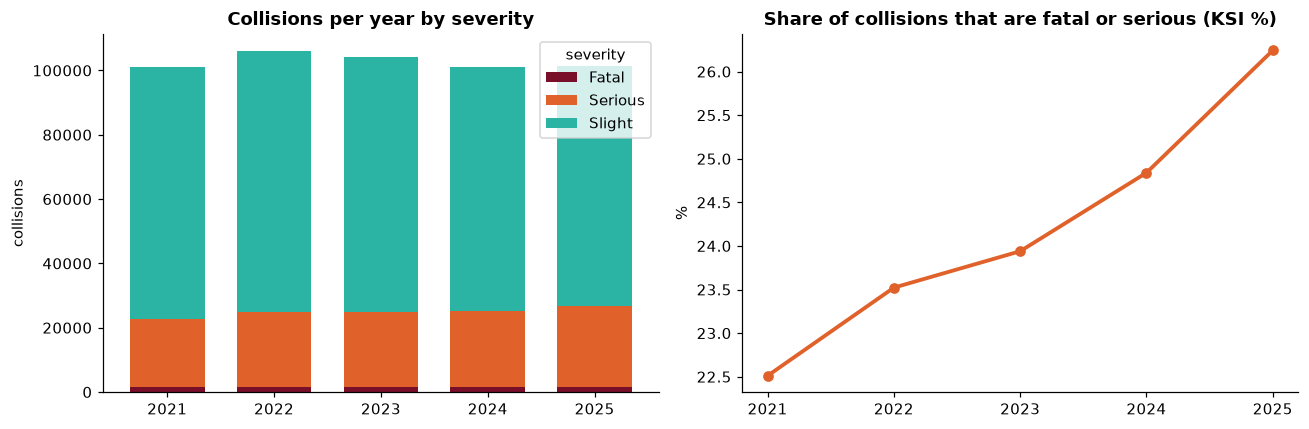

severity,Fatal,Serious,Slight,total,ksi_pct
collision_year,,,,,
2021,1473,21279,78318,101070,22.51
2022,1602,23327,81053,105982,23.52
2023,1522,23434,79290,104246,23.94
2024,1502,23567,75856,100925,24.84
2025,1453,25189,74880,101522,26.24


In [15]:
SEV_ORDER = ["Fatal", "Serious", "Slight"]
yearly = (gb.groupBy("collision_year", "severity").count().toPandas()
          .pivot(index="collision_year", columns="severity", values="count")[SEV_ORDER])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
yearly.plot(kind="bar", stacked=True, color=[SEV_COLORS[s] for s in SEV_ORDER], ax=axes[0], width=0.7)
axes[0].set_title("Collisions per year by severity"); axes[0].set_xlabel(""); axes[0].set_ylabel("collisions")
axes[0].tick_params(axis="x", rotation=0)
ksi_share = (100 * yearly[["Fatal", "Serious"]].sum(axis=1) / yearly.sum(axis=1))
axes[1].plot(yearly.index, ksi_share, marker="o", color=ORANGE, lw=2.5)
axes[1].set_title("Share of collisions that are fatal or serious (KSI %)"); axes[1].set_ylabel("%")
axes[1].set_xticks(yearly.index)
savefig("eda_yearly_severity")
display(yearly.assign(total=yearly.sum(axis=1), ksi_pct=ksi_share.round(2)))

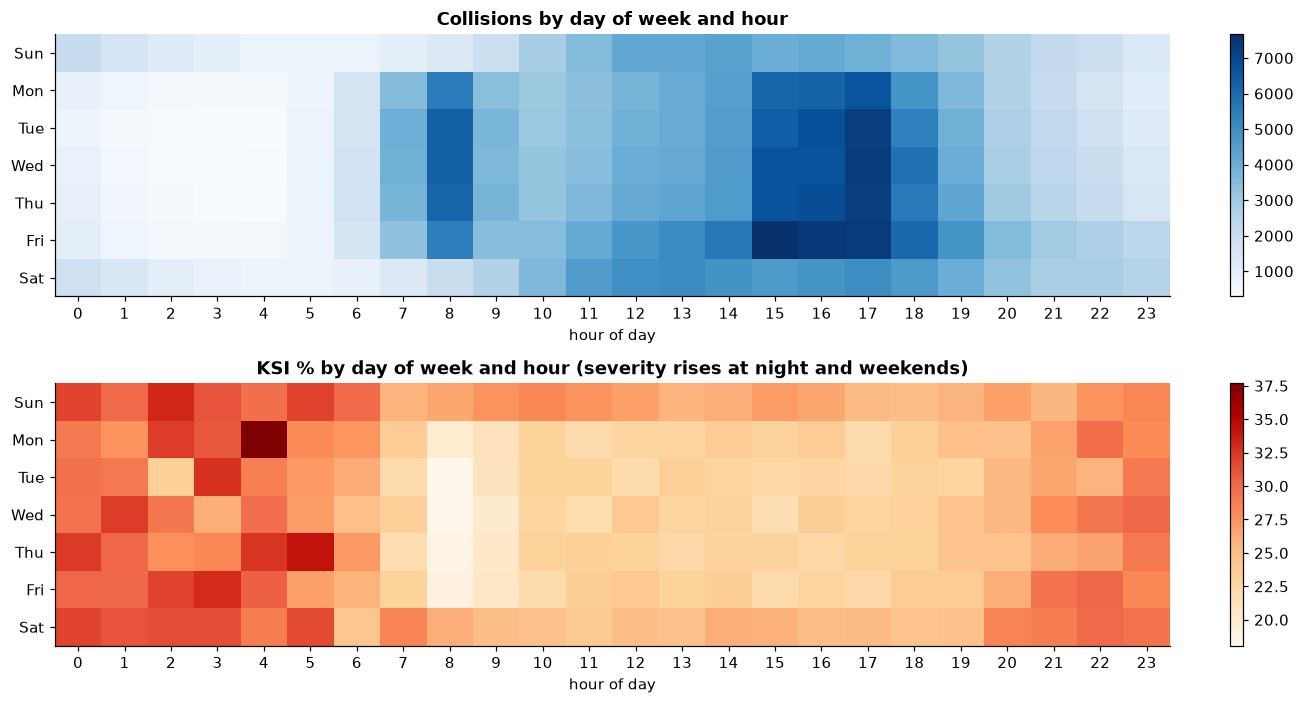

In [16]:
DOW = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
hd = gb.groupBy("day_of_week", "hour").agg(F.count("*").alias("n"), F.avg("ksi").alias("ksi_rate")).toPandas()
counts = hd.pivot(index="day_of_week", columns="hour", values="n").reindex(range(1, 8))
ksi_rate = hd.pivot(index="day_of_week", columns="hour", values="ksi_rate").reindex(range(1, 8)) * 100
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5))
for ax, mat, title, cmap in [(axes[0], counts, "Collisions by day of week and hour", "Blues"),
                             (axes[1], ksi_rate, "KSI % by day of week and hour (severity rises at night and weekends)", "OrRd")]:
    im = ax.imshow(mat.values, aspect="auto", cmap=cmap)
    ax.set_yticks(range(7)); ax.set_yticklabels(DOW); ax.set_xticks(range(24)); ax.set_xlabel("hour of day")
    ax.set_title(title); plt.colorbar(im, ax=ax, fraction=0.025)
savefig("eda_hour_day_heatmaps")

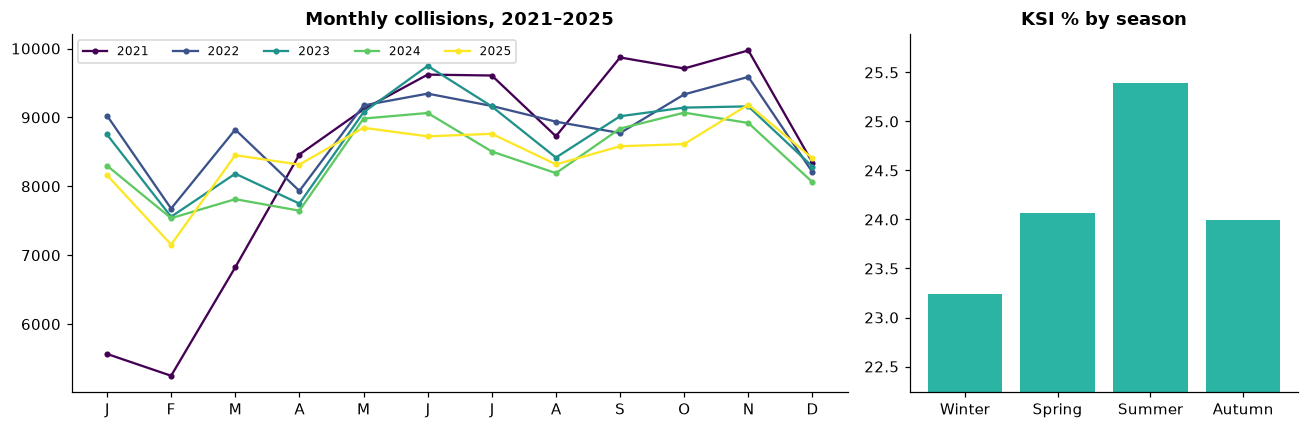

,collisions,ksi_pct
season,,
Winter,116284,23.24
Spring,125396,24.07
Summer,134293,25.39
Autumn,137772,23.99


In [17]:
monthly = gb.groupBy("collision_year", "month").count().toPandas().pivot(index="month", columns="collision_year", values="count")
season_tab = gb.groupBy("season").agg(F.count("*").alias("collisions"), F.round(100 * F.avg("ksi"), 2).alias("ksi_pct")).toPandas()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
for i, y in enumerate(monthly.columns):
    axes[0].plot(monthly.index, monthly[y], marker="o", ms=3, label=str(y), color=plt.cm.viridis(i / 4))
axes[0].set_xticks(range(1, 13)); axes[0].set_xticklabels(list("JFMAMJJASOND")); axes[0].legend(ncol=5, fontsize=8)
axes[0].set_title("Monthly collisions, 2021–2025")
season_tab = season_tab.set_index("season").loc[["Winter", "Spring", "Summer", "Autumn"]]
axes[1].bar(season_tab.index, season_tab.ksi_pct, color=TEAL)
axes[1].set_ylim(season_tab.ksi_pct.min() - 1, season_tab.ksi_pct.max() + 0.5)
axes[1].set_title("KSI % by season")
savefig("eda_monthly_seasonal")
season_tab

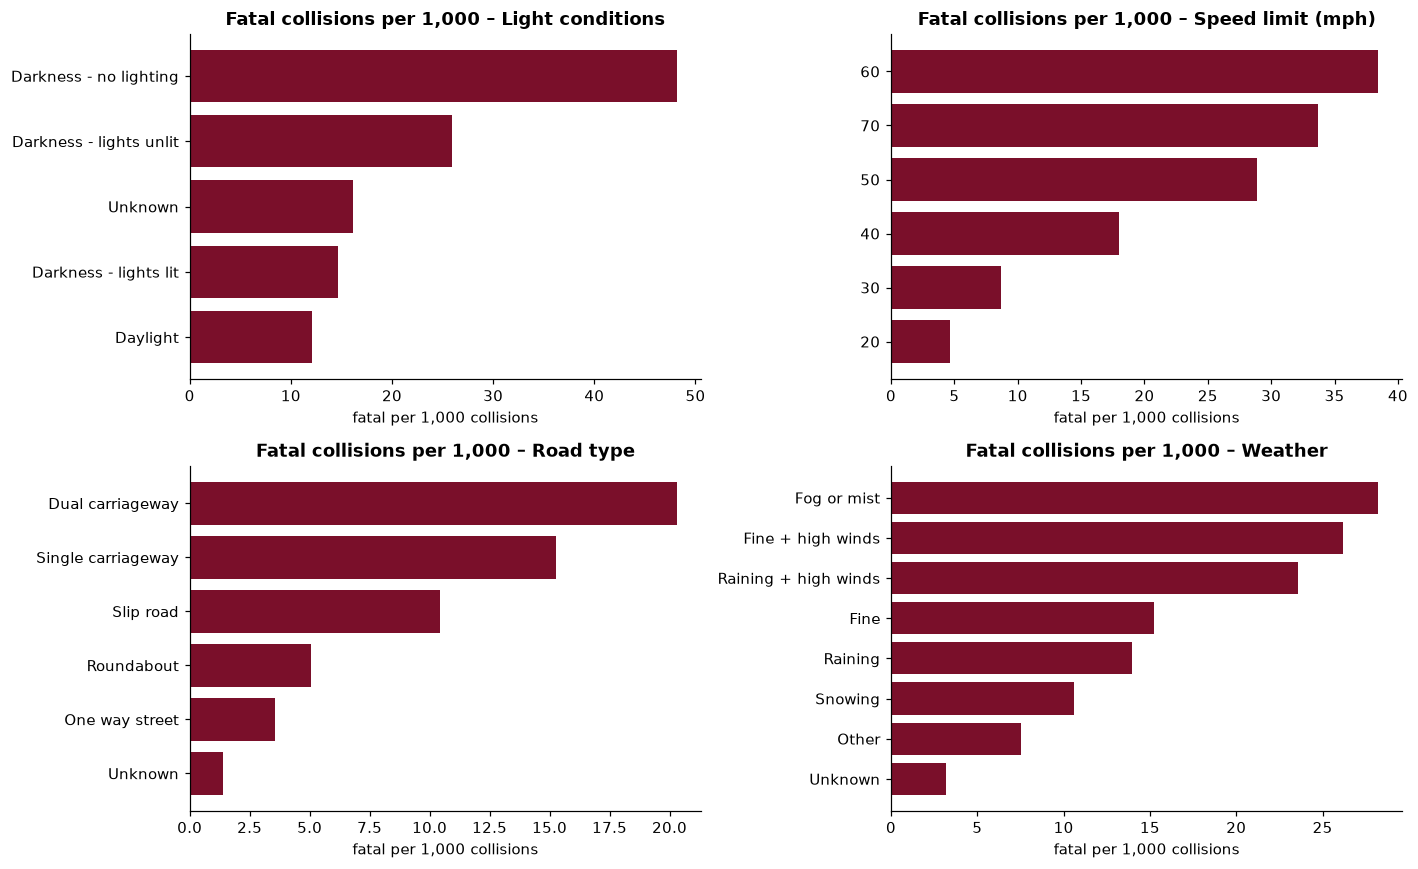

,urban_or_rural_area_label,collisions,ksi_pct,fatal_per_1000
0,Rural,168426,29.36,28.34
1,Urban,345314,21.69,8.05


In [18]:
def ksi_by(field, min_n=500):
    t = (gb.groupBy(field).agg(F.count("*").alias("collisions"), F.round(100 * F.avg("ksi"), 2).alias("ksi_pct"),
                               F.round(1000 * F.avg((F.col("collision_severity") == 1).cast("int")), 2).alias("fatal_per_1000"))
         .filter(F.col("collisions") >= min_n).orderBy(F.desc("ksi_pct")).toPandas())
    return t

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, field, title in [(axes[0, 0], "light_conditions_label", "Light conditions"),
                         (axes[0, 1], "speed_limit", "Speed limit (mph)"),
                         (axes[1, 0], "road_type_label", "Road type"),
                         (axes[1, 1], "weather_conditions_label", "Weather")]:
    t = ksi_by(field).sort_values("fatal_per_1000")
    ax.barh(t[field].astype(str), t.fatal_per_1000, color=SEV_COLORS["Fatal"])
    ax.set_title(f"Fatal collisions per 1,000 – {title}"); ax.set_xlabel("fatal per 1,000 collisions")
savefig("eda_conditions_fatality")
ksi_by("urban_or_rural_area_label")

**Observations.** Collision numbers peak in the weekday afternoon commute, but *severity* peaks at night and at
weekends. Darkness without street lighting, 60 mph rural roads and 70 mph roads have far higher fatality rates than
urban 20–30 mph roads. Rural collisions are fewer but much more likely to be fatal. These patterns motivate the
hotspot analysis (where) and the severity model (which conditions).

## 7. Step 4a – Hotspot analysis: where do crashes, and severe crashes, cluster?
Four complementary methods:

| Method | Question it answers | Engine |
|---|---|---|
| 7.1 Grid screening (95th percentile) | Which 5 km cells have unusually many collisions, and are they persistent, emerging or declining? | Spark SQL |
| 7.2 **Getis-Ord Gi\*** | Which cells are statistically significant hot spots of KSI collisions? | Sedona `stats` |
| 7.3 **K-Means** | What are the main regional concentrations of severe crashes? | Spark MLlib |
| 7.4 **DBSCAN** | Where are dense, local clusters of fatal / KSI crashes (with noise removed)? | Sedona `stats` (distributed) |

In [19]:
cell_year = (gb.groupBy("grid_id", "grid_x", "grid_y", "collision_year")
             .agg(F.count("*").alias("n"), F.sum("ksi").alias("ksi"),
                  F.sum((F.col("collision_severity") == 1).cast("int")).alias("fatal")))
threshold = cell_year.approxQuantile("n", [0.95], 0.0)[0]
cy = cell_year.toPandas()
wide = cy.pivot_table(index=["grid_id", "grid_x", "grid_y"], columns="collision_year", values="n", fill_value=0)
years = sorted(cy.collision_year.unique())
high = wide >= threshold
def temporal_category(row):
    h = row.values
    if h.all(): return "Persistent"
    if not h.any(): return "Never high-count"
    if (not h[0]) and h[-1]: return "Emerging"
    if h[0] and (not h[-1]): return "Declining"
    return "Variable"
grid = wide.copy(); grid.columns = [f"n_{y}" for y in years]
grid["high_years"] = high.sum(axis=1); grid["temporal_category"] = high.apply(temporal_category, axis=1)
grid = grid.reset_index()
print(f"Occupied 5 km cells: {len(grid):,} | 95th-percentile threshold: {threshold:.0f} collisions per cell-year | "
      f"high-count cell-years: {int(high.values.sum()):,}")
grid.temporal_category.value_counts().rename("cells").to_frame()

Occupied 5 km cells: 7,617 | 95th-percentile threshold: 64 collisions per cell-year | high-count cell-years: 1,566


,cells
temporal_category,
Never high-count,7231
Persistent,257
Variable,68
Emerging,34
Declining,27


In [20]:
from sedona.stats.weighting import add_binary_distance_band_column
from sedona.stats.hotspot_detection.getis_ord import g_local

cells = (gb.groupBy("grid_id", "grid_x", "grid_y")
         .agg(F.count("*").alias("collisions"), F.sum("ksi").alias("ksi"),
              F.sum((F.col("collision_severity") == 1).cast("int")).alias("fatal"))
         .withColumn("geometry", F.expr(f"ST_Point((grid_x + 0.5) * {GRID_M}, (grid_y + 0.5) * {GRID_M})")))
weighted = add_binary_distance_band_column(cells, GI_BAND_M, include_self=True, saved_attributes=None)
gi = (g_local(weighted, "ksi", weights="weights", star=True)
      .select("grid_id", "collisions", "ksi", "fatal", "G", "Z", "P").toPandas())

# Benjamini–Hochberg false-discovery-rate correction for ~7,600 simultaneous tests
def bh_adjust(p):
    p = np.asarray(p, dtype=float); n = len(p); idx = np.argsort(p)
    ranked = p[idx] * n / np.arange(1, n + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1]
    out = np.empty(n); out[idx] = np.minimum(ranked, 1.0)
    return out
gi["p_fdr"] = bh_adjust(gi.P)
def gi_class(r):
    if r.Z > 0 and r.p_fdr < 0.01: return "Hot spot (99%)"
    if r.Z > 0 and r.p_fdr < 0.05: return "Hot spot (95%)"
    if r.Z < 0 and r.p_fdr < 0.05: return "Cold spot (95%)"
    return "Not significant"
gi["gi_class"] = gi.apply(gi_class, axis=1)
grid = grid.merge(gi, on="grid_id", how="left")
print("Getis-Ord Gi* on KSI counts (5 km cells, 8-neighbour band, FDR-corrected):")
grid.gi_class.value_counts().rename("cells").to_frame()

Getis-Ord Gi* on KSI counts (5 km cells, 8-neighbour band, FDR-corrected):


,cells
gi_class,
Not significant,7256
Hot spot (99%),278
Hot spot (95%),83


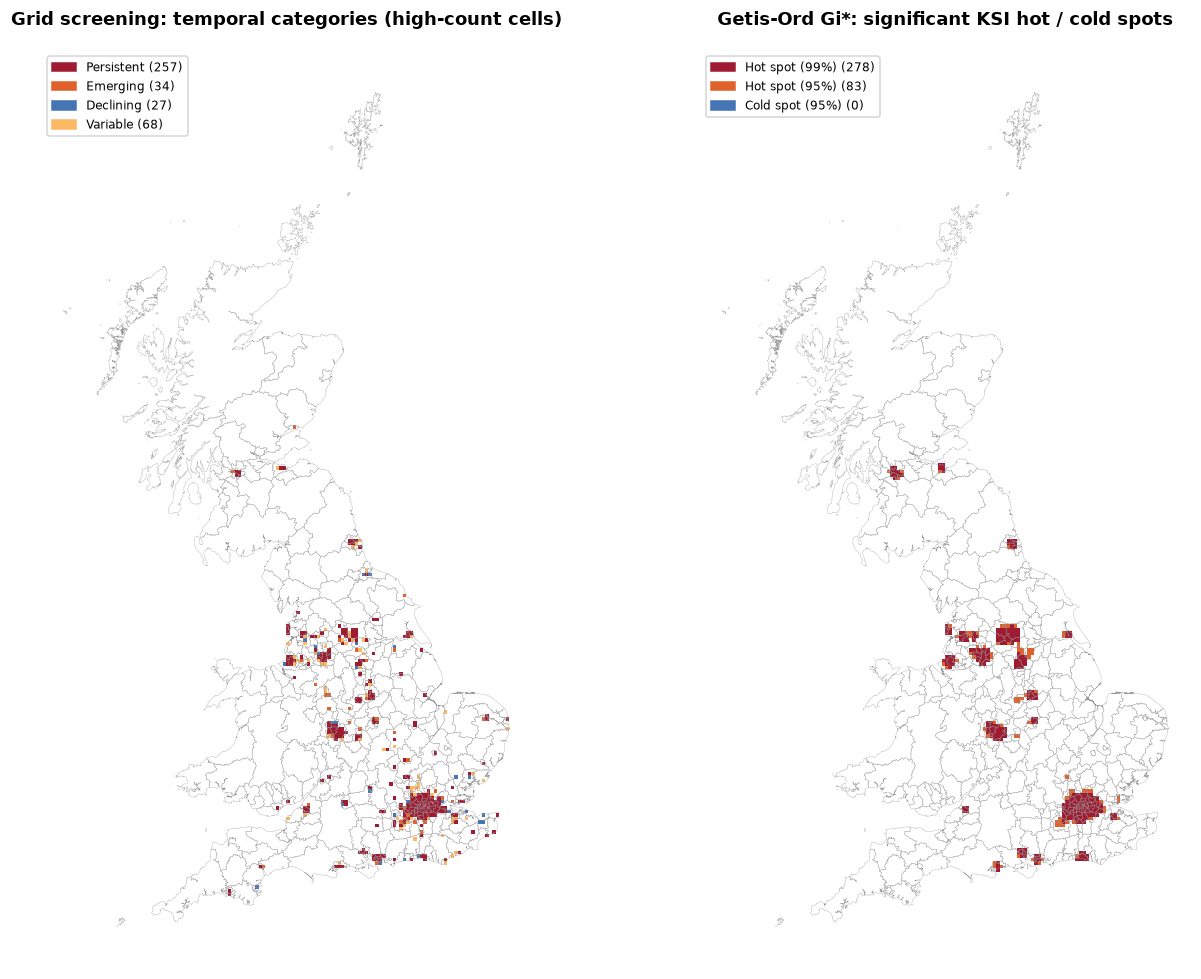

In [21]:
lad_bng = lad_gdf.to_crs(27700)
lad_outline = lad_bng.copy(); lad_outline["geometry"] = lad_outline.geometry.simplify(300)
from shapely.geometry import box
def cell_gdf(df_):
    return gpd.GeoDataFrame(df_, geometry=[box(x * GRID_M, y * GRID_M, (x + 1) * GRID_M, (y + 1) * GRID_M)
                                          for x, y in zip(df_.grid_x, df_.grid_y)], crs=27700)
grid_g = cell_gdf(grid)
fig, axes = plt.subplots(1, 2, figsize=(13, 9))
cat_colors = {"Persistent": "#9e1b32", "Emerging": ORANGE, "Declining": "#4575b4", "Variable": "#fdb863"}
gi_colors = {"Hot spot (99%)": "#9e1b32", "Hot spot (95%)": ORANGE, "Cold spot (95%)": "#4575b4"}
for ax, col, cmap, title in [(axes[0], "temporal_category", cat_colors, "Grid screening: temporal categories (high-count cells)"),
                             (axes[1], "gi_class", gi_colors, "Getis-Ord Gi*: significant KSI hot / cold spots")]:
    lad_outline.boundary.plot(ax=ax, lw=0.2, color="#999999")
    for k, c in cmap.items():
        sub = grid_g[grid_g[col] == k]
        if len(sub): sub.plot(ax=ax, color=c, lw=0)
    ax.legend(handles=[mpatches.Patch(color=c, label=f"{k} ({(grid_g[col]==k).sum()})") for k, c in cmap.items()],
              loc="upper left", fontsize=8)
    ax.set_title(title); ax.set_axis_off()
savefig("hotspots_grid_and_gistar")

### 7.3 K-Means (Spark MLlib) – regional concentrations of KSI collisions
K-Means is run on the projected coordinates (km) of the fatal and serious collisions. The number of clusters is
chosen with the elbow method (largest bend in the within-cluster cost curve), and the silhouette score is
reported. K-Means divides all severe crashes into compact regions, so it identifies *regional concentrations*,
not isolated hotspots.

Chosen k (elbow): 15


,k,cost,silhouette
0,5,6.557689e+08,0.631
1,10,3.200027e+08,0.638
2,15,2.270633e+08,0.605
3,20,1.619001e+08,0.601
4,25,1.324690e+08,0.591
5,30,1.038844e+08,0.620
6,40,7.455142e+07,0.606
7,50,5.851064e+07,0.610


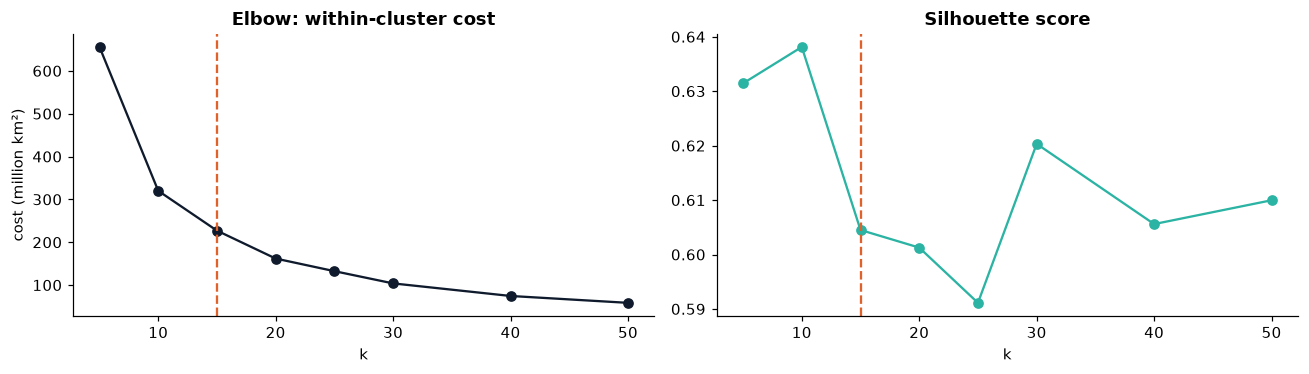

,kmeans_cluster,ksi_collisions,fatal,easting,northing,main_district,fatal_share_pct
0,3,36252,1393,536851.369082,172066.998242,Westminster,3.84
1,6,12146,637,429818.448696,414207.191893,Leeds,5.24
2,5,10157,745,403274.007629,274888.631046,Birmingham,7.33
3,9,9737,697,354812.993524,382439.548916,Manchester,7.16
4,0,9201,541,441677.958796,127589.626506,Wiltshire,5.88
5,10,8713,690,470714.949389,310253.621078,Nottingham,7.92
6,14,6196,436,592502.700153,272741.423955,East Suffolk,7.04
7,11,6091,508,315966.002915,192186.656756,"Bristol, City of",8.34
8,4,5300,256,352289.023368,445554.423379,Preston,4.83
9,1,4950,385,422407.405132,546406.540008,County Durham,7.78


In [22]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

ksi_pts = (gb.filter("ksi = 1")
           .select("collision_index", "collision_severity", "lad_name", "easting", "northing")
           .withColumn("e_km", F.col("easting") / 1000).withColumn("n_km", F.col("northing") / 1000))
ksi_vec = VectorAssembler(inputCols=["e_km", "n_km"], outputCol="features").transform(ksi_pts).persist(StorageLevel.MEMORY_AND_DISK)
ksi_vec.count()
evaluator = ClusteringEvaluator(featuresCol="features", metricName="silhouette")
K_GRID = [5, 10, 15, 20, 25, 30, 40, 50]
km_scan = []
for k in K_GRID:
    mdl = KMeans(k=k, seed=SEED, maxIter=40, featuresCol="features").fit(ksi_vec)
    km_scan.append({"k": k, "cost": mdl.summary.trainingCost,
                    "silhouette": evaluator.evaluate(mdl.transform(ksi_vec))})
km_scan = pd.DataFrame(km_scan)
# elbow = point of maximum distance from the line joining the first and last cost values
x = (km_scan.k - km_scan.k.min()) / (km_scan.k.max() - km_scan.k.min())
y = (km_scan.cost - km_scan.cost.min()) / (km_scan.cost.max() - km_scan.cost.min())
K_BEST = int(km_scan.k[np.argmax(np.abs(1 - x - y))])
print("Chosen k (elbow):", K_BEST)
display(km_scan.round(3))

kmeans_model = KMeans(k=K_BEST, seed=SEED, maxIter=60, featuresCol="features").fit(ksi_vec)
km_assign = kmeans_model.transform(ksi_vec).select("collision_index", F.col("prediction").alias("kmeans_cluster"),
                                                   "collision_severity", "lad_name", "easting", "northing")
km_profile = (km_assign.groupBy("kmeans_cluster")
              .agg(F.count("*").alias("ksi_collisions"), F.sum((F.col("collision_severity") == 1).cast("int")).alias("fatal"),
                   F.avg("easting").alias("easting"), F.avg("northing").alias("northing"),
                   F.mode("lad_name").alias("main_district"))
              .withColumn("fatal_share_pct", F.round(100 * F.col("fatal") / F.col("ksi_collisions"), 2))
              .orderBy(F.desc("ksi_collisions")).toPandas())
km_assign_pd = km_assign.select("collision_index", "kmeans_cluster").toPandas()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].plot(km_scan.k, km_scan.cost / 1e6, marker="o", color=NAVY); axes[0].axvline(K_BEST, color=ORANGE, ls="--")
axes[0].set_title("Elbow: within-cluster cost"); axes[0].set_xlabel("k"); axes[0].set_ylabel("cost (million km²)")
axes[1].plot(km_scan.k, km_scan.silhouette, marker="o", color=TEAL); axes[1].axvline(K_BEST, color=ORANGE, ls="--")
axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
savefig("kmeans_model_selection")
km_profile.head(10)

### 7.4 DBSCAN (Apache Sedona, distributed) – dense local clusters
Sedona's DBSCAN runs as a distributed distance self-join, followed by connected components (GraphFrames).
Two scales are used:
* **Fatal clusters:** `eps = 1 km`, `min_pts = 4` → places with at least 4 fatal collisions chained within 1 km.
* **KSI junction clusters:** `eps = 150 m`, `min_pts = 12` → junction and short-segment clusters of severe crashes.

Collisions that do not belong to any dense cluster are labelled noise (`cluster = -1`). This is DBSCAN's
advantage over K-Means: it does not force every crash into a cluster.

In [23]:
from sedona.stats.clustering.dbscan import dbscan

def run_dbscan(filter_sql, params, name):
    pts = gb.filter(filter_sql).select("collision_index", "collision_severity", "collision_year", "lad_name",
                                       F.col("geom_bng").alias("geometry"))
    t0 = time.time()
    res = dbscan(pts, params["epsilon"], params["min_pts"], geometry="geometry", include_outliers=True)
    res = res.persist(StorageLevel.MEMORY_AND_DISK)
    clustered = res.filter("cluster != -1")
    summary = (clustered.groupBy("cluster")
               .agg(F.count("*").alias("collisions"),
                    F.sum((F.col("collision_severity") == 1).cast("int")).alias("fatal"),
                    F.min("collision_year").alias("first_year"), F.max("collision_year").alias("last_year"),
                    F.mode("lad_name").alias("district"),
                    F.expr("ST_AsText(ST_Transform(ST_Centroid(ST_Union_Aggr(geometry)), 'EPSG:27700', 'EPSG:4326'))").alias("centroid_wkt"),
                    F.expr("ST_AsGeoJSON(ST_Transform(ST_Buffer(ST_ConvexHull(ST_Union_Aggr(geometry)), 60), 'EPSG:27700', 'EPSG:4326'))").alias("hull_geojson"))
               .orderBy(F.desc("collisions")).toPandas())
    summary["lon"] = summary.centroid_wkt.str.extract(r"POINT \(([-\d\.]+)").astype(float)
    summary["lat"] = summary.centroid_wkt.str.extract(r"POINT \([-\d\.]+ ([-\d\.]+)").astype(float)
    n_in = int(summary.collisions.sum()); n_all = res.count()
    print(f"{name}: {len(summary)} clusters | {n_in:,} of {n_all:,} points clustered "
          f"({100*n_in/n_all:.1f}%) | largest cluster {summary.collisions.max()} | {time.time()-t0:.0f} s")
    members = clustered.select("collision_index", "cluster").toPandas()   # small: clustered points only
    res.unpersist()
    return members, summary.drop(columns="centroid_wkt")

fatal_db, fatal_clusters = run_dbscan("collision_severity = 1", DBSCAN_FATAL, "DBSCAN fatal")
ksi_db, ksi_clusters = run_dbscan("ksi = 1", DBSCAN_KSI, "DBSCAN KSI")
display(fatal_clusters[["cluster", "collisions", "fatal", "district", "first_year", "last_year", "lat", "lon"]].head(10))
display(ksi_clusters[["cluster", "collisions", "fatal", "district", "lat", "lon"]].head(10))

DBSCAN fatal: 114 clusters | 614 of 7,552 points clustered (8.1%) | largest cluster 17 | 80 s


DBSCAN KSI: 186 clusters | 3,848 of 124,348 points clustered (3.1%) | largest cluster 130 | 94 s


,cluster,collisions,fatal,district,first_year,last_year,lat,lon
0,8589934595,17,17,Birmingham,2021,2025,52.496524,-1.878080
1,8589934604,14,14,Manchester,2022,2025,53.473066,-2.236660
2,8,12,12,Kensington and Chelsea,2021,2025,51.493304,-0.205816
3,8589934600,11,11,Westminster,2021,2025,51.517450,-0.133575
4,0,11,11,Tower Hamlets,2021,2025,51.513337,-0.053380
5,68719476746,10,10,Southwark,2021,2025,51.496025,-0.101585
6,51539607562,9,9,Manchester,2021,2025,53.447896,-2.243453
7,146028888068,9,9,Newham,2021,2025,51.526282,0.032508
8,85899345928,9,9,Enfield,2022,2025,51.611259,-0.050896
9,42949672961,9,9,Epping Forest,2021,2024,51.680634,0.041766


,cluster,collisions,fatal,district,lat,lon
0,16,130,2,Westminster,51.510078,-0.130621
1,8589934646,93,1,Hackney,51.525237,-0.080600
2,33,76,1,Westminster,51.515024,-0.145148
3,21,71,5,Lambeth,51.461607,-0.115274
4,54,61,2,Lambeth,51.463984,-0.132466
5,9,60,2,Southwark,51.494432,-0.098717
6,17,58,1,Westminster,51.516532,-0.130582
7,13,56,0,City of London,51.514568,-0.104660
8,56,55,2,Nottingham,52.955838,-1.145307
9,18,54,2,Brighton and Hove,50.821535,-0.136114


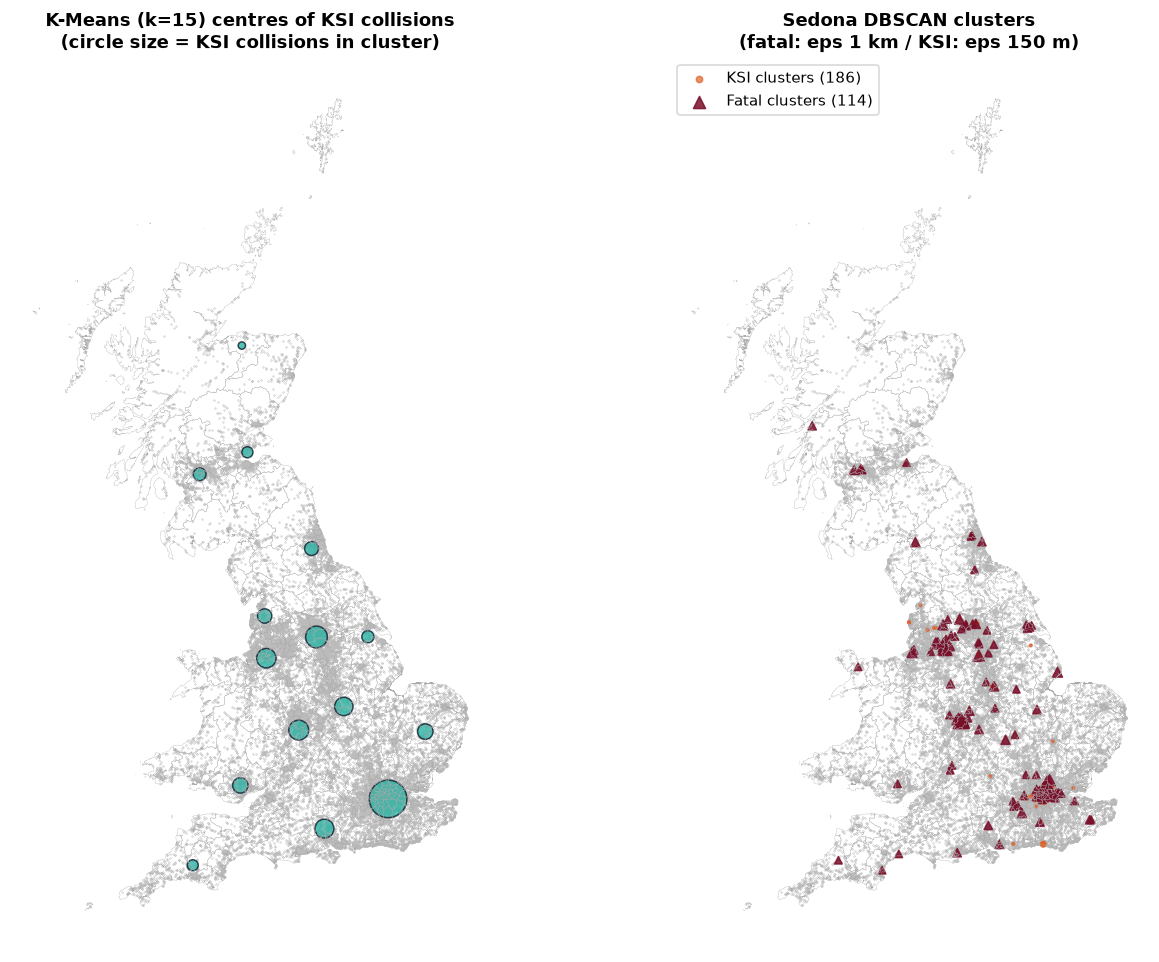

In [24]:
from pyproj import Transformer
to_bng = Transformer.from_crs(4326, 27700, always_xy=True)
km_centers = np.array(kmeans_model.clusterCenters()) * 1000
fig, axes = plt.subplots(1, 2, figsize=(13, 9))
ksi_sample = gb.filter("ksi = 1").sample(0.35, seed=SEED).select("easting", "northing").toPandas()
for ax in axes:
    lad_outline.boundary.plot(ax=ax, lw=0.2, color="#aaaaaa")
    ax.scatter(ksi_sample.easting, ksi_sample.northing, s=0.1, color="#bbbbbb", rasterized=True)
    ax.set_axis_off()
axes[0].scatter(km_centers[:, 0], km_centers[:, 1], s=km_profile.set_index("kmeans_cluster").loc[range(K_BEST), "ksi_collisions"] / 60,
                color=TEAL, ec=NAVY, alpha=0.8)
axes[0].set_title(f"K-Means (k={K_BEST}) centres of KSI collisions\n(circle size = KSI collisions in cluster)")
fx, fy = to_bng.transform(fatal_clusters.lon.values, fatal_clusters.lat.values)
kx, ky = to_bng.transform(ksi_clusters.lon.values, ksi_clusters.lat.values)
axes[1].scatter(kx, ky, s=ksi_clusters.collisions / 4, color=ORANGE, alpha=0.7, label=f"KSI clusters ({len(ksi_clusters)})")
axes[1].scatter(fx, fy, s=fatal_clusters.collisions * 6, color=SEV_COLORS["Fatal"], marker="^", alpha=0.85,
                label=f"Fatal clusters ({len(fatal_clusters)})")
axes[1].legend(loc="upper left"); axes[1].set_title("Sedona DBSCAN clusters\n(fatal: eps 1 km / KSI: eps 150 m)")
savefig("clusters_kmeans_dbscan")

### 7.5 Which areas are most fatal? District-level severity
Counts show where most fatal crashes happen. Rates (fatal per 1,000 collisions, KSI %) show where a crash is most
likely to be severe. Rural districts dominate the rate ranking even though urban districts dominate the counts.

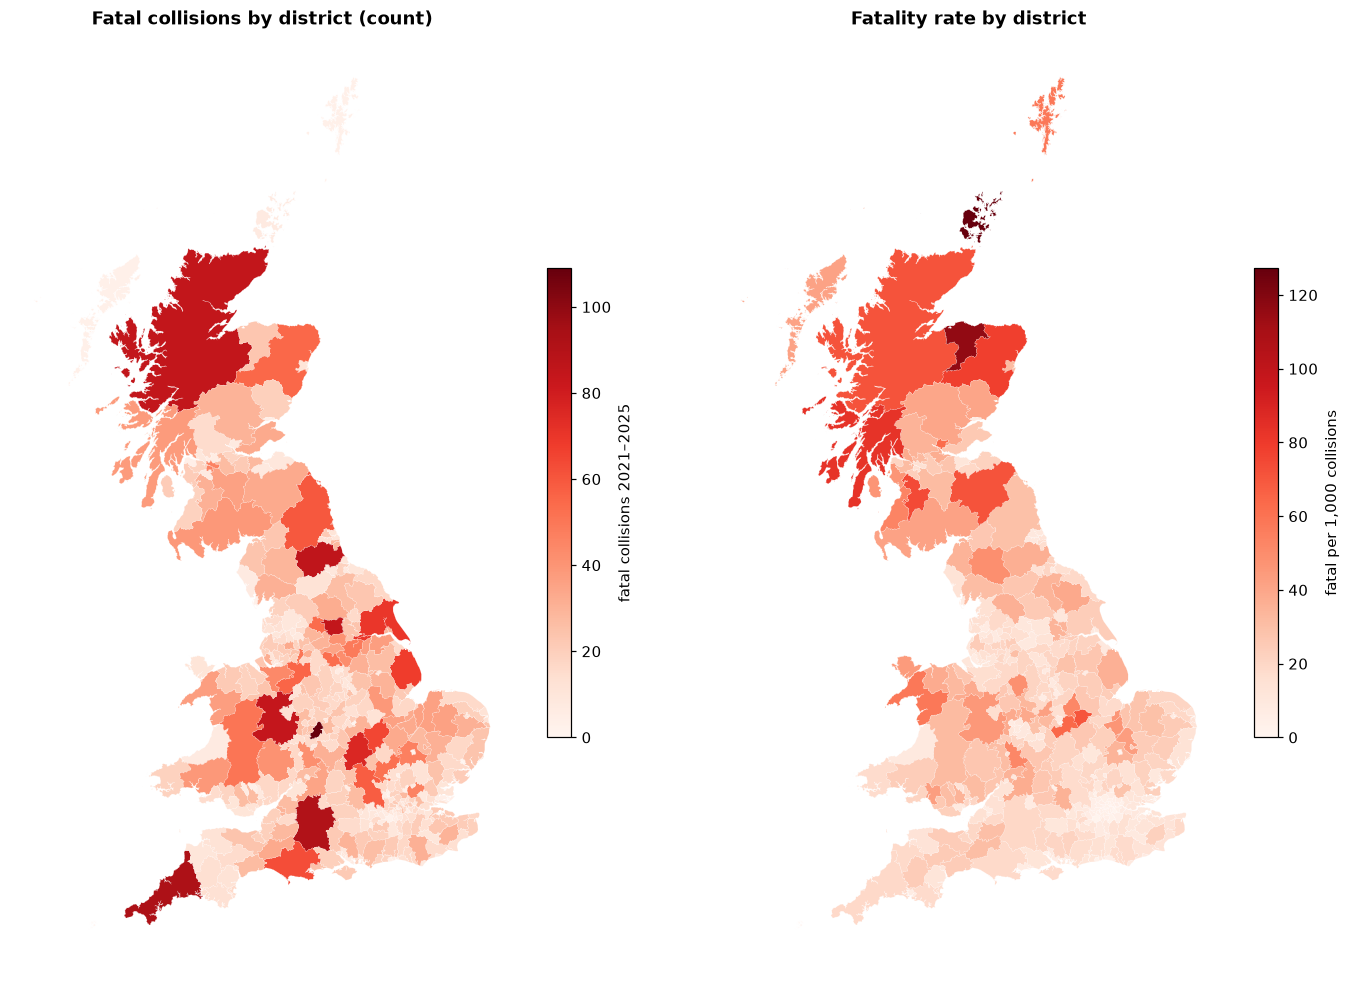

Most fatal collisions (count):


,lad_name,collisions,fatal,fatal_per_1000,ksi_pct
105,Birmingham,11311,109,9.64,18.88
359,Cornwall,4851,92,18.97,23.67
130,Wiltshire,4651,91,19.57,20.17
155,County Durham,2369,86,36.30,37.40
80,Highland,1190,85,71.43,55.88
316,Leeds,7295,85,11.65,29.68
194,Shropshire,1846,84,45.50,33.10
107,West Northamptonshire,3630,76,20.94,20.83
254,East Riding of Yorkshire,2931,70,23.88,27.33
195,East Lindsey,1888,68,36.02,24.74


Highest fatality rate (districts with ≥ 500 collisions):


,lad_name,collisions,fatal,fatal_per_1000,ksi_pct
136,Aberdeenshire,702,55,78.35,62.82
80,Highland,1190,85,71.43,55.88
38,Gwynedd,637,37,58.08,43.80
30,Wychavon,811,42,51.79,35.88
260,Eden,594,29,48.82,34.51
332,Fenland,707,33,46.68,28.01
194,Shropshire,1846,84,45.50,33.10
186,East Cambridgeshire,643,28,43.55,31.10
196,North West Leicestershire,565,24,42.48,32.39
210,Dumfries and Galloway,941,39,41.45,40.81


In [25]:
lad_stats = (gb.groupBy("lad_code", "lad_name")
             .agg(F.count("*").alias("collisions"), F.sum("ksi").alias("ksi"),
                  F.sum((F.col("collision_severity") == 1).cast("int")).alias("fatal"),
                  F.sum((F.col("collision_severity") == 2).cast("int")).alias("serious"))
             .toPandas())
lad_stats["ksi_pct"] = 100 * lad_stats.ksi / lad_stats.collisions
lad_stats["fatal_per_1000"] = 1000 * lad_stats.fatal / lad_stats.collisions
lad_stats = lad_stats.merge(lad_bng[["lad_code"]].assign(area_km2=lad_bng.area / 1e6), on="lad_code")
lad_stats["fatal_per_100km2"] = 100 * lad_stats.fatal / lad_stats.area_km2
lad_map = lad_outline.merge(lad_stats, on=["lad_code", "lad_name"], how="left")
fig, axes = plt.subplots(1, 2, figsize=(13, 9))
lad_map.plot(column="fatal", cmap="Reds", ax=axes[0], legend=True, lw=0.1, edgecolor="white",
             legend_kwds={"shrink": 0.5, "label": "fatal collisions 2021–2025"})
lad_map.plot(column="fatal_per_1000", cmap="Reds", ax=axes[1], legend=True, lw=0.1, edgecolor="white",
             legend_kwds={"shrink": 0.5, "label": "fatal per 1,000 collisions"})
axes[0].set_title("Fatal collisions by district (count)"); axes[1].set_title("Fatality rate by district")
for ax in axes: ax.set_axis_off()
savefig("districts_fatal_count_rate")
print("Most fatal collisions (count):")
display(lad_stats.nlargest(10, "fatal")[["lad_name", "collisions", "fatal", "fatal_per_1000", "ksi_pct"]].round(2))
print("Highest fatality rate (districts with ≥ 500 collisions):")
display(lad_stats[lad_stats.collisions >= 500].nlargest(10, "fatal_per_1000")[["lad_name", "collisions", "fatal", "fatal_per_1000", "ksi_pct"]].round(2))

## 8. Step 4b – Severity classification (Spark MLlib)
**Target:** collision severity (Fatal / Serious / Slight). **Split:** chronological – train 2021–2024, test 2025
(the model is evaluated on a year it has never seen). **Class imbalance:** about 1.5 % Fatal and 23 % Serious, so
inverse-frequency class weights are computed from the training years only.

**Features** – conditions recorded for the collision: time (hour, day, month, weekend), road (class, type, speed
limit, trunk flag), junction (detail, control, pedestrian crossing), environment (light, weather, surface,
carriageway hazards), urban/rural and police force area. Outcome-related fields (number of casualties, vehicles,
police attendance) are deliberately excluded to avoid leakage.

**Models:** multinomial Logistic Regression (unweighted and class-weighted), class-weighted **Random Forest**
(main model), and a class-weighted **Gradient-Boosted Trees** binary model for KSI vs Slight (MLlib GBT is binary).

In [26]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier, GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, confusion_matrix,
                             roc_auc_score, average_precision_score)

FEATURES = ["hour", "day_of_week", "month", "is_weekend", "first_road_class", "road_type", "speed_limit",
            "junction_detail", "junction_control", "pedestrian_crossing", "light_conditions", "weather_conditions",
            "road_surface_conditions", "carriageway_hazards", "urban_or_rural_area", "trunk_road_flag", "police_force"]
CLASS_NAMES = ["Fatal", "Serious", "Slight"]

model_df = (gb.select("collision_index", "collision_year", "lad_code", "lad_name", "h3_cell", "collision_severity", *FEATURES)
            .fillna(-1, subset=FEATURES)
            .withColumn("label", (F.col("collision_severity") - 1).cast("double"))
            .withColumn("ksi_label", (F.col("collision_severity") <= 2).cast("double")))
train = model_df.filter(F.col("collision_year") < TEST_YEAR)
test = model_df.filter(F.col("collision_year") == TEST_YEAR)
cls_counts = train.groupBy("label").count().toPandas().set_index("label")["count"].sort_index()
n_train = int(cls_counts.sum())
class_w = {float(k): n_train / (3 * v) for k, v in cls_counts.items()}
ksi_counts = train.groupBy("ksi_label").count().toPandas().set_index("ksi_label")["count"]
bin_w = {float(k): n_train / (2 * v) for k, v in ksi_counts.items()}
wmap = F.create_map([F.lit(x) for x in chain(*class_w.items())])
bmap = F.create_map([F.lit(x) for x in chain(*bin_w.items())])
train = train.withColumn("w", wmap[F.col("label")]).withColumn("w_bin", bmap[F.col("ksi_label")])
print(f"Train 2021–2024: {n_train:,} | test {TEST_YEAR}: {test.count():,}")
pd.DataFrame({"train_count": cls_counts.values, "class_weight": [round(class_w[k], 3) for k in cls_counts.index]},
             index=CLASS_NAMES)

Train 2021–2024: 412,223 | test 2025: 101,522


,train_count,class_weight
Fatal,6099,22.530
Serious,91607,1.500
Slight,314517,0.437


In [27]:
# Ordinal features (hour, month, speed limit, weekend flag) enter the trees as numbers, so a split such as
# "hour >= 22" is possible; nominal codes are indexed as categories. Logistic Regression one-hot encodes all.
ORDINAL = ["hour", "month", "speed_limit", "is_weekend"]
NOMINAL = [f for f in FEATURES if f not in ORDINAL]
IDX = [f + "_idx" for f in FEATURES]; OHE = [f + "_ohe" for f in FEATURES]
TREE_INPUTS = [f if f in ORDINAL else f + "_idx" for f in FEATURES]   # same order as FEATURES
prep = Pipeline(stages=[
    StringIndexer(inputCols=FEATURES, outputCols=IDX, handleInvalid="keep"),
    OneHotEncoder(inputCols=IDX, outputCols=OHE, handleInvalid="keep"),
    VectorAssembler(inputCols=TREE_INPUTS, outputCol="features_tree"),
    VectorAssembler(inputCols=OHE, outputCol="features_lr"),
]).fit(train)
train_p = prep.transform(train).select("label", "ksi_label", "w", "w_bin", "features_tree", "features_lr").persist(StorageLevel.MEMORY_AND_DISK)
test_p = prep.transform(test).select("collision_index", "lad_code", "lad_name", "h3_cell", "label", "ksi_label",
                                     "features_tree", "features_lr").persist(StorageLevel.MEMORY_AND_DISK)
train_p.count(); test_p.count()

def eval_multiclass(pred, name, secs):
    pdf = pred.select("label", "prediction").toPandas()
    y, p = pdf.label.astype(int), pdf.prediction.astype(int)
    rec = recall_score(y, p, labels=[0, 1, 2], average=None, zero_division=0)
    prec = precision_score(y, p, labels=[0, 1, 2], average=None, zero_division=0)
    return {"Model": name, "Accuracy": accuracy_score(y, p), "Weighted F1": f1_score(y, p, average="weighted"),
            "Macro F1": f1_score(y, p, average="macro"), "Fatal recall": rec[0], "Serious recall": rec[1],
            "Slight recall": rec[2], "Fatal precision": prec[0], "Serious precision": prec[1],
            "Train seconds": round(secs, 1)}, confusion_matrix(y, p, labels=[0, 1, 2])

results, confusions, fitted = [], {}, {}
specs = [
    ("Logistic Regression", LogisticRegression(featuresCol="features_lr", labelCol="label", maxIter=100, family="multinomial")),
    ("Class-Weighted Logistic Regression", LogisticRegression(featuresCol="features_lr", labelCol="label", weightCol="w", maxIter=100, family="multinomial")),
    ("Class-Weighted Random Forest", RandomForestClassifier(featuresCol="features_tree", labelCol="label", weightCol="w", numTrees=100,
                                                            maxDepth=10, maxBins=64, featureSubsetStrategy="sqrt", subsamplingRate=0.8, seed=SEED)),
]
for name, est in specs:
    t0 = time.time(); mdl = est.fit(train_p); secs = time.time() - t0
    res, cm = eval_multiclass(mdl.transform(test_p), name, secs)
    results.append(res); confusions[name] = cm; fitted[name] = mdl
    print(f"{name:38s} macro F1 {res['Macro F1']:.4f} | fatal recall {res['Fatal recall']:.3f} | {secs:.0f} s")
comparison = pd.DataFrame(results)
comparison.round(4)

Logistic Regression                    macro F1 0.2889 | fatal recall 0.000 | 19 s


Class-Weighted Logistic Regression     macro F1 0.3345 | fatal recall 0.616 | 12 s


Class-Weighted Random Forest           macro F1 0.3461 | fatal recall 0.551 | 210 s


,Model,Accuracy,Weighted F1,Macro F1,Fatal recall,Serious recall,Slight recall,Fatal precision,Serious precision,Train seconds
0,Logistic Regression,0.7375,0.6304,0.2889,0.0000,0.0091,0.9968,0.0000,0.4440,18.9
1,Class-Weighted Logistic Regression,0.4709,0.5429,0.3345,0.6160,0.3186,0.5193,0.0341,0.2976,11.9
2,Class-Weighted Random Forest,0.5103,0.5691,0.3461,0.5513,0.2993,0.5804,0.0379,0.2951,210.5


In [28]:
t0 = time.time()
gbt = GBTClassifier(featuresCol="features_tree", labelCol="ksi_label", weightCol="w_bin", maxIter=60, maxDepth=6,
                    maxBins=64, stepSize=0.1, seed=SEED).fit(train_p)
gbt_secs = time.time() - t0
gbt_pred = gbt.transform(test_p).withColumn("p_ksi", vector_to_array("probability")[1])
rf_pred = (fitted["Class-Weighted Random Forest"].transform(test_p)
           .withColumn("p", vector_to_array("probability"))
           .withColumn("p_fatal", F.col("p")[0]).withColumn("p_ksi", F.col("p")[0] + F.col("p")[1]))
g = gbt_pred.select("ksi_label", "prediction", "p_ksi").toPandas()
r = rf_pred.select("ksi_label", "p_ksi").toPandas()
binary = pd.DataFrame([
    {"Model": "Class-Weighted GBT (KSI vs Slight)", "ROC AUC": roc_auc_score(g.ksi_label, g.p_ksi),
     "PR AUC": average_precision_score(g.ksi_label, g.p_ksi), "KSI recall": recall_score(g.ksi_label, g.prediction),
     "KSI precision": precision_score(g.ksi_label, g.prediction), "KSI F1": f1_score(g.ksi_label, g.prediction),
     "Train seconds": round(gbt_secs, 1)},
    {"Model": "Class-Weighted RF (P(Fatal)+P(Serious))", "ROC AUC": roc_auc_score(r.ksi_label, r.p_ksi),
     "PR AUC": average_precision_score(r.ksi_label, r.p_ksi), "KSI recall": recall_score(r.ksi_label, r.p_ksi >= 0.5),
     "KSI precision": precision_score(r.ksi_label, r.p_ksi >= 0.5), "KSI F1": f1_score(r.ksi_label, r.p_ksi >= 0.5),
     "Train seconds": np.nan},
])
print(f"Base rate of KSI in {TEST_YEAR}: {g.ksi_label.mean():.3f} (PR AUC of a random model)")
binary.round(4)

Base rate of KSI in 2025: 0.262 (PR AUC of a random model)


,Model,ROC AUC,PR AUC,KSI recall,KSI precision,KSI F1,Train seconds
0,Class-Weighted GBT (KSI vs Slight),0.6159,0.3606,0.5706,0.3325,0.4202,56.0
1,Class-Weighted RF (P(Fatal)+P(Serious)),0.6044,0.3471,0.9286,0.2806,0.4310,NaN


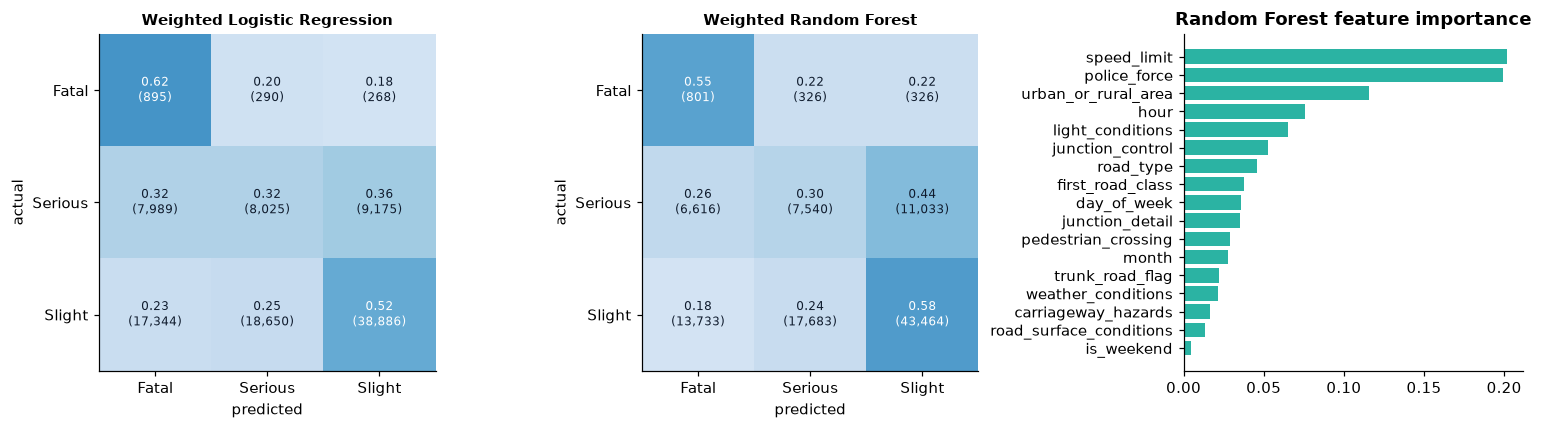

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, name in zip(axes[:2], ["Class-Weighted Logistic Regression", "Class-Weighted Random Forest"]):
    cm = confusions[name]; cmn = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cmn[i, j]:.2f}\n({cm[i, j]:,})", ha="center", va="center", fontsize=8,
                    color="white" if cmn[i, j] > 0.5 else NAVY)
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("predicted"); ax.set_ylabel("actual"); ax.set_title(name.replace("Class-Weighted", "Weighted"), fontsize=10)
imp = pd.Series(fitted["Class-Weighted Random Forest"].featureImportances.toArray(), index=FEATURES).sort_values()
axes[2].barh(imp.index, imp.values, color=TEAL); axes[2].set_title("Random Forest feature importance")
savefig("severity_confusion_importance")

**Reading the feature importance.** `police_force` ranks highly, but this is partly a *recording* effect, not
only a road-danger effect. Since 2016 many forces report through the CRASH system, which classifies injuries
from injury type and records more of them as *serious* than officer judgement did. Police Scotland and other
forces differ in how they adopted it. DfT publishes "adjusted" severity figures for this reason. Speed limit,
urban/rural location and light conditions are the strongest *road-environment* drivers of severity.

### 8.1 Which areas have the highest predicted severity risk?
The class-weighted Random Forest gives every 2025 collision a predicted probability of being fatal or serious.
Averaging these probabilities by district gives a **predicted severity risk index** (district mean ÷ national
mean; > 1 means collisions there are predicted to be more severe than average). This index is compared with the
KSI rate actually observed in 2025.

Spearman correlation between predicted risk index and observed 2025 KSI rate across 363 districts: 0.659


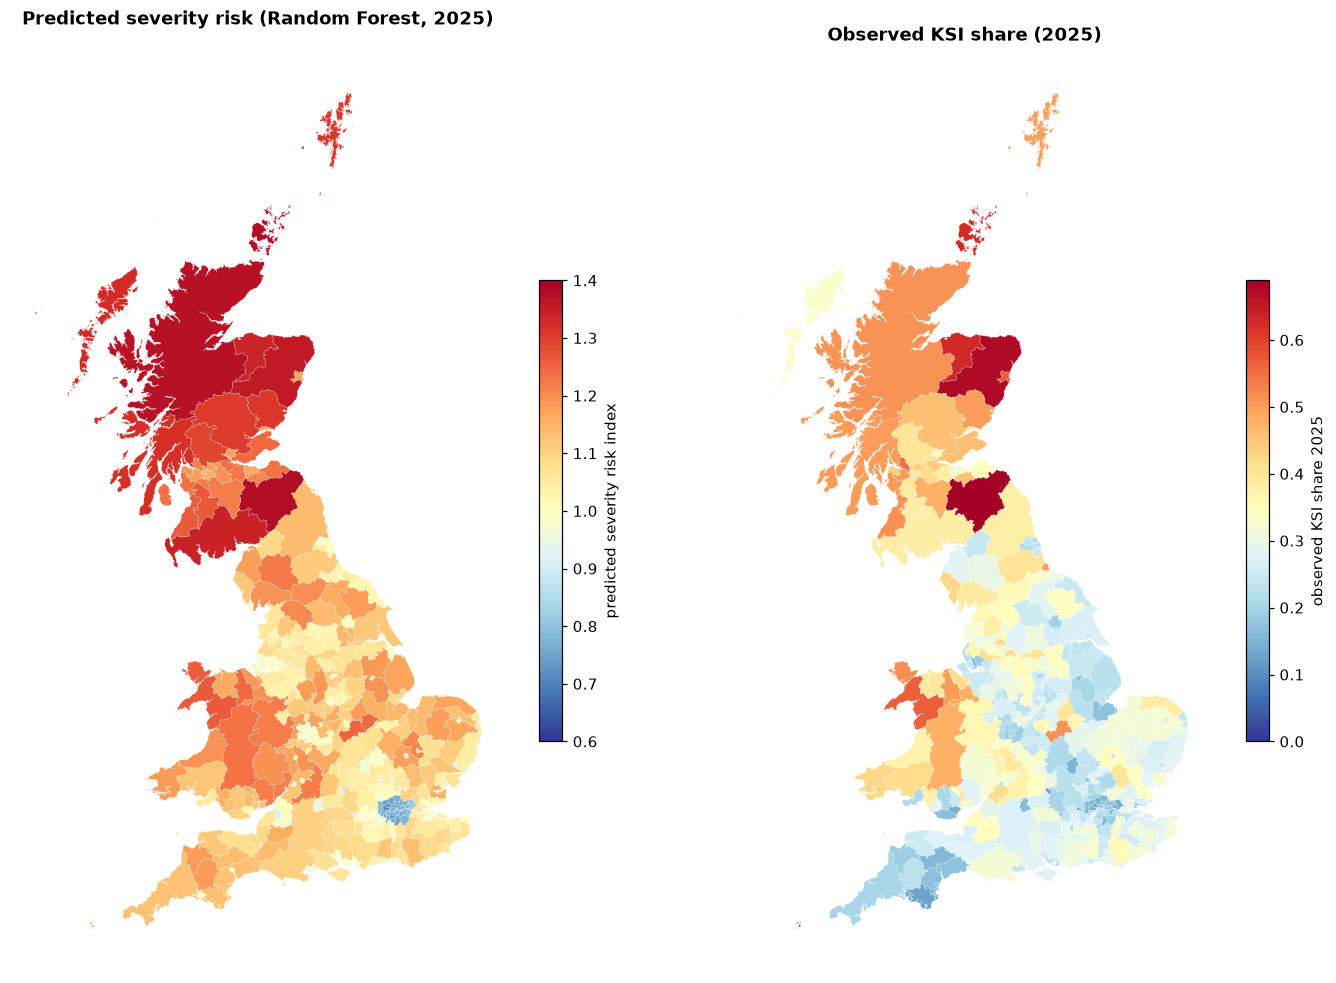

,lad_code,lad_name,test_collisions,mean_p_ksi,mean_p_fatal,observed_ksi_rate_2025,risk_index
80,S12000017,Highland,245,0.831,0.538,0.510,1.369
137,S12000034,Aberdeenshire,123,0.821,0.516,0.675,1.353
210,S12000006,Dumfries and Galloway,222,0.814,0.504,0.383,1.341
277,S12000048,Perth and Kinross,166,0.792,0.466,0.458,1.305
38,W06000002,Gwynedd,106,0.766,0.442,0.566,1.263
60,E07000131,Harborough,110,0.760,0.464,0.509,1.252
177,S12000047,Fife,275,0.756,0.399,0.458,1.246
274,W06000023,Powys,321,0.749,0.404,0.477,1.234
236,S12000040,West Lothian,165,0.745,0.370,0.382,1.228
260,E07000030,Eden,114,0.743,0.433,0.298,1.223


In [30]:
national_p = rf_pred.agg(F.avg("p_ksi")).first()[0]
lad_risk = (rf_pred.groupBy("lad_code", "lad_name")
            .agg(F.count("*").alias("test_collisions"), F.avg("p_ksi").alias("mean_p_ksi"), F.avg("p_fatal").alias("mean_p_fatal"),
                 F.avg(F.when(F.col("label") <= 1, 1).otherwise(0)).alias("observed_ksi_rate_2025"))
            .toPandas())
lad_risk["risk_index"] = lad_risk.mean_p_ksi / national_p
h3_risk = (rf_pred.groupBy("h3_cell").agg(F.count("*").alias("test_collisions"), F.avg("p_ksi").alias("mean_p_ksi"),
                                          F.avg(F.when(F.col("label") <= 1, 1).otherwise(0)).alias("observed_ksi_rate_2025"))
           .toPandas())
h3_risk["risk_index"] = h3_risk.mean_p_ksi / national_p
from scipy.stats import spearmanr
rho = spearmanr(lad_risk.risk_index, lad_risk.observed_ksi_rate_2025).correlation
print(f"Spearman correlation between predicted risk index and observed 2025 KSI rate across {len(lad_risk)} districts: {rho:.3f}")
risk_map = lad_outline.merge(lad_risk, on=["lad_code", "lad_name"], how="left")
fig, axes = plt.subplots(1, 2, figsize=(13, 9))
risk_map.plot(column="risk_index", cmap="RdYlBu_r", ax=axes[0], legend=True, lw=0.1, edgecolor="white",
              vmin=0.6, vmax=1.4, legend_kwds={"shrink": 0.5, "label": "predicted severity risk index"})
risk_map.plot(column="observed_ksi_rate_2025", cmap="RdYlBu_r", ax=axes[1], legend=True, lw=0.1, edgecolor="white",
              legend_kwds={"shrink": 0.5, "label": "observed KSI share 2025"})
axes[0].set_title("Predicted severity risk (Random Forest, 2025)"); axes[1].set_title("Observed KSI share (2025)")
for ax in axes: ax.set_axis_off()
savefig("districts_predicted_vs_observed_risk")
lad_risk[lad_risk.test_collisions >= 100].nlargest(10, "risk_index").round(3)

In [31]:
prep.write().overwrite().save(str(MODELS / "spark_feature_pipeline"))
fitted["Class-Weighted Random Forest"].write().overwrite().save(str(MODELS / "spark_rf_severity"))
gbt.write().overwrite().save(str(MODELS / "spark_gbt_ksi"))
comparison.to_csv(DOCS / "model_comparison.csv", index=False)
binary.to_csv(DOCS / "model_binary_ksi.csv", index=False)
imp.sort_values(ascending=False).rename("importance").to_csv(DOCS / "rf_feature_importance.csv")
print("Spark models saved to", MODELS)

Spark models saved to C:\Users\LANKA PRIYA\Downloads\Road_Accident_Project\Final_Project\models


### 8.2 Deployable predictor for the dashboard
A Spark model needs a JVM and a Spark session, and Streamlit Community Cloud cannot provide those. For the
dashboard's interactive **severity predictor**, the same features, chronological split and class weighting are
used to train a scikit-learn `HistGradientBoostingClassifier`. It is a single file of a few MB that loads in
milliseconds. It is evaluated on the same 2025 test set so that it can be compared directly with the Spark models.

In [32]:
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier

NUM_COLS = ["hour", "month", "speed_limit", "is_weekend"]
CAT_COLS = [f for f in FEATURES if f not in NUM_COLS]
pdf = model_df.select("collision_year", "collision_severity", *FEATURES).toPandas()
CATEGORIES = {c: sorted(int(v) for v in pdf[c].unique()) for c in CAT_COLS}

def to_X(d):
    X = d[FEATURES].copy()
    for c in CAT_COLS:
        X[c] = pd.Categorical(X[c].astype(int), categories=CATEGORIES[c])
    return X

tr, te = pdf[pdf.collision_year < TEST_YEAR], pdf[pdf.collision_year == TEST_YEAR]
t0 = time.time()
hgb = HistGradientBoostingClassifier(categorical_features="from_dtype", class_weight="balanced", max_iter=400,
                                     learning_rate=0.08, max_leaf_nodes=31, l2_regularization=1.0,
                                     early_stopping=True, validation_fraction=0.1, random_state=SEED)
hgb.fit(to_X(tr), tr.collision_severity)
hgb_secs = time.time() - t0
proba = hgb.predict_proba(to_X(te)); pred = hgb.classes_[proba.argmax(1)]
y_te = te.collision_severity.values
rec = recall_score(y_te, pred, labels=[1, 2, 3], average=None)
hgb_row = {"Model": "HistGradientBoosting (dashboard predictor)", "Accuracy": accuracy_score(y_te, pred),
           "Weighted F1": f1_score(y_te, pred, average="weighted"), "Macro F1": f1_score(y_te, pred, average="macro"),
           "Fatal recall": rec[0], "Serious recall": rec[1], "Slight recall": rec[2],
           "Fatal precision": precision_score(y_te, pred, labels=[1], average=None)[0],
           "Serious precision": precision_score(y_te, pred, labels=[2], average=None)[0], "Train seconds": round(hgb_secs, 1)}
comparison_all = pd.concat([comparison, pd.DataFrame([hgb_row])], ignore_index=True)
p_ksi_test = proba[:, 0] + proba[:, 1]
print(f"Predictor trained in {hgb_secs:.0f} s, {hgb.n_iter_} boosting iterations")
comparison_all.round(4)

Predictor trained in 7 s, 54 boosting iterations


,Model,Accuracy,Weighted F1,Macro F1,Fatal recall,Serious recall,Slight recall,Fatal precision,Serious precision,Train seconds
0,Logistic Regression,0.7375,0.6304,0.2889,0.0000,0.0091,0.9968,0.0000,0.4440,18.9
1,Class-Weighted Logistic Regression,0.4709,0.5429,0.3345,0.6160,0.3186,0.5193,0.0341,0.2976,11.9
2,Class-Weighted Random Forest,0.5103,0.5691,0.3461,0.5513,0.2993,0.5804,0.0379,0.2951,210.5
3,HistGradientBoosting (dashboard predictor),0.4902,0.5556,0.3435,0.5630,0.3390,0.5397,0.0365,0.2962,6.6


In [33]:
def code_options(field):
    present = CATEGORIES.get(field) or sorted(int(v) for v in pdf[field].unique())
    labels = LABELS.get(field, {})
    return {str(c): labels.get(c, str(c)) for c in present}

predictor_meta = {
    "features": FEATURES, "numeric": NUM_COLS, "categorical": CAT_COLS, "categories": CATEGORIES,
    "classes": {"1": "Fatal", "2": "Serious", "3": "Slight"},
    "options": {f: code_options(f) for f in CAT_COLS + ["speed_limit"]},
    "defaults": {f: int(pdf[f].mode()[0]) for f in FEATURES},
    "p_ksi_test_quantiles": {str(q): float(np.quantile(p_ksi_test, q / 100)) for q in range(0, 101)},
    "base_rates_train": {CLASS_NAMES[int(k)]: float(v / n_train) for k, v in cls_counts.items()},
    "test_year": TEST_YEAR, "metrics": {k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in hgb_row.items()},
    "sklearn_version": sklearn.__version__,
}
joblib.dump(hgb, DASH / "severity_predictor.joblib", compress=3)
jdump(predictor_meta, DASH / "predictor_metadata.json")
comparison_all.to_csv(DOCS / "model_comparison.csv", index=False)
print(f"severity_predictor.joblib: {(DASH / 'severity_predictor.joblib').stat().st_size / 1e6:.2f} MB")

severity_predictor.joblib: 0.27 MB


## 9. Step 4c – Association rules (Spark MLlib FP-Growth)
Each collision becomes a *transaction* of readable items, for example `Weather=Raining`,
`Light=Darkness - no lighting`, `Road class=Motorway`, `Speed=60 mph`, `Time=Night (00–05)`, `Severity=Fatal`.
Unknown values are dropped. FP-Growth finds frequent itemsets (support ≥ 0.2 %, i.e. ≥ ~1,000 collisions) and
rules `antecedent → consequent`, with:
* **support** – share of all collisions containing the whole rule;
* **confidence** – P(consequent | antecedent);
* **lift** – confidence ÷ base rate of the consequent (lift 3 = three times more likely than average).

The focus is on rules whose consequent is a severity level, i.e. *which combinations of conditions go with
severe outcomes*. Rules describe co-occurrence, not causation.

In [34]:
from pyspark.ml.fpm import FPGrowth

def item(prefix, col):
    return F.when(col.isNotNull() & ~col.isin("Unknown", "Other", "None"), F.concat(F.lit(prefix + "="), col))

light_grp = (F.when(F.col("light_conditions") == 1, "Daylight").when(F.col("light_conditions") == 4, "Darkness - lights lit")
             .when(F.col("light_conditions").isin(5, 6), "Darkness - unlit or no lighting"))
tx = gb.select("collision_index", F.array_compact(F.array(
    item("Severity", F.col("severity")),
    item("Light", light_grp),
    item("Weather", F.col("weather_conditions_label")),
    item("Surface", F.col("road_surface_conditions_label")),
    item("Road type", F.col("road_type_label")),
    item("Road class", F.col("first_road_class_label")),
    item("Speed", F.when(F.col("speed_limit") > 0, F.concat(F.col("speed_limit").cast("string"), F.lit(" mph")))),
    item("Junction", F.col("junction_detail_label")),
    item("Control", F.col("junction_control_label")),
    item("Area", F.col("urban_or_rural_area_label")),
    item("Time", F.col("time_band")),
    item("Day", F.when(F.col("is_weekend") == 1, "Weekend").otherwise("Weekday")),
    item("Season", F.col("season")),
)).alias("items")).persist(StorageLevel.MEMORY_AND_DISK)
print(f"Transactions: {tx.count():,} | mean items per transaction: {tx.select(F.avg(F.size('items'))).first()[0]:.1f}")

t0 = time.time()
fp = FPGrowth(itemsCol="items", minSupport=FP_MIN_SUPPORT, minConfidence=FP_MIN_CONFIDENCE).fit(tx)
n_itemsets = fp.freqItemsets.count()
rules_all = fp.associationRules.filter(F.size("antecedent") <= 3)
sev_rules = (rules_all.filter(F.size("consequent") == 1).filter(F.col("consequent")[0].startswith("Severity="))
             .filter(~F.exists("antecedent", lambda x: x.startswith("Severity=")))
             .withColumn("consequent", F.col("consequent")[0])
             .withColumn("antecedent_size", F.size("antecedent")))
rules = sev_rules.toPandas()
fp_secs = time.time() - t0
rules["antecedent"] = rules.antecedent.apply(lambda a: " AND ".join(sorted(a)))
rules["severity"] = rules.consequent.str.replace("Severity=", "")
rules["support_count"] = (rules.support * n_gb).round().astype(int)
print(f"FP-Growth: {n_itemsets:,} frequent itemsets | {len(rules):,} severity rules (antecedent ≤ 3 items) | {fp_secs:.0f} s")
rules.groupby("severity").agg(rules=("lift", "size"), max_lift=("lift", "max"), max_confidence=("confidence", "max")).round(3)

Transactions: 513,745 | mean items per transaction: 12.4


FP-Growth: 468,190 frequent itemsets | 11,649 severity rules (antecedent ≤ 3 items) | 78 s


,rules,max_lift,max_confidence
severity,,,
Fatal,302,3.884,0.057
Serious,4358,1.677,0.381
Slight,6989,1.191,0.903


In [35]:
# Non-redundant view: drop a rule if a simpler rule (subset antecedent, same consequent) already has >= its lift
from itertools import combinations
def prune(df_):
    keep = []
    for sev, grp in df_.groupby("severity"):
        best = {}
        for idx, r in grp.sort_values("antecedent_size").iterrows():
            items = frozenset(r.antecedent.split(" AND "))
            subsets = [frozenset(c) for k in range(1, len(items)) for c in combinations(items, k)]
            if not any(best.get(s, -np.inf) >= r.lift for s in subsets):
                keep.append(idx)
            best[items] = max(r.lift, max((best.get(s, -np.inf) for s in subsets), default=-np.inf))
    return df_.loc[keep]

pruned = prune(rules[rules.lift > 1.05])
print(f"Non-redundant rules with lift > 1.05: {len(pruned):,}")
for sev in ["Fatal", "Serious"]:
    print(f"\nTop rules → {sev} (by lift)")
    display(pruned[pruned.severity == sev].nlargest(8, "lift")[["antecedent", "support_count", "confidence", "lift"]].round(3))

Non-redundant rules with lift > 1.05: 1,357

Top rules → Fatal (by lift)


,antecedent,support_count,confidence,lift
10702,Area=Rural AND Junction=Not at junction AND Li...,1162,0.057,3.884
2225,Junction=Not at junction AND Road class=A AND ...,1109,0.055,3.735
3792,Road class=A AND Road type=Single carriageway ...,1327,0.054,3.687
9869,Junction=Not at junction AND Light=Darkness - ...,1243,0.054,3.682
9699,Road class=A AND Speed=60 mph AND Weather=Fine,1204,0.050,3.431
5321,Light=Darkness - unlit or no lighting AND Weat...,1074,0.050,3.408
1138,Area=Rural AND Light=Darkness - unlit or no li...,1309,0.050,3.406
2082,Area=Rural AND Road class=A AND Speed=60 mph,1403,0.049,3.348



Top rules → Serious (by lift)


,antecedent,support_count,confidence,lift
2959,Day=Weekend AND Season=Summer AND Speed=60 mph,2025,0.381,1.677
3406,Day=Weekend AND Road class=B AND Speed=60 mph,1247,0.380,1.671
6152,Day=Weekend AND Season=Spring AND Speed=60 mph,1660,0.373,1.641
1607,Day=Weekend AND Speed=60 mph AND Time=Daytime ...,2849,0.372,1.635
633,Day=Weekend AND Speed=60 mph AND Surface=Dry,4462,0.370,1.629
1930,Road class=B AND Season=Summer AND Speed=60 mph,1168,0.368,1.620
11164,Road class=B AND Speed=60 mph AND Time=Daytime...,1457,0.366,1.609
5081,Road class=B AND Speed=60 mph AND Surface=Dry,2540,0.364,1.602


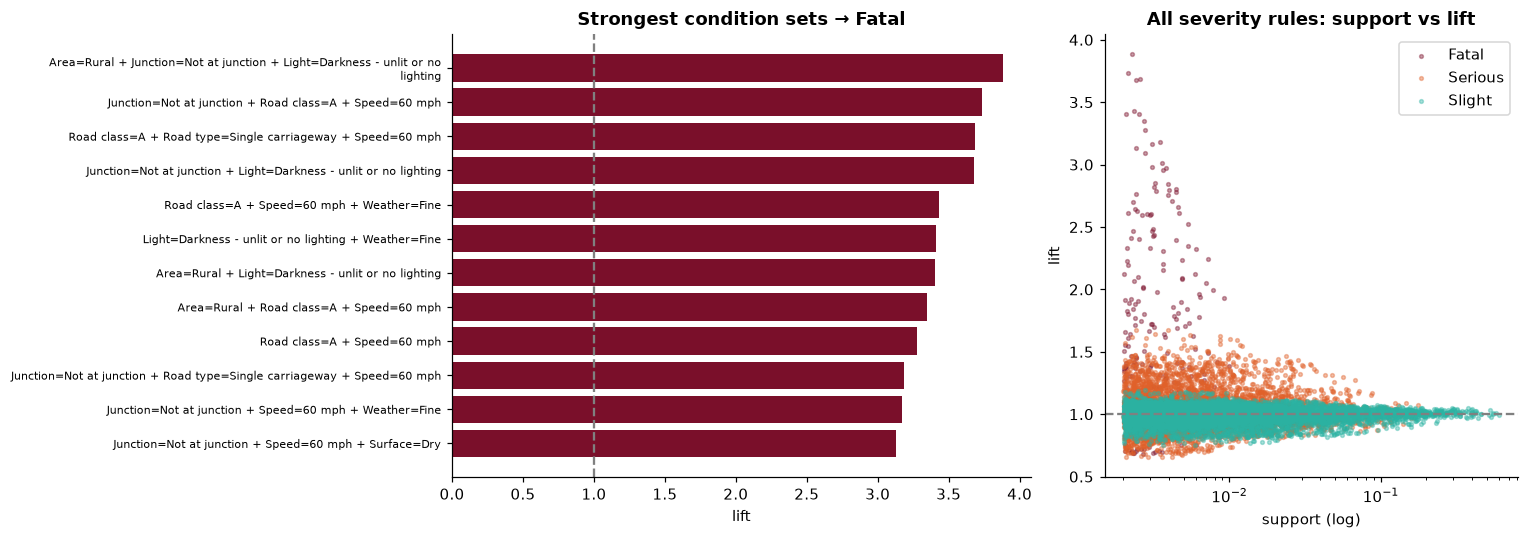

In [36]:
top_f = pruned[pruned.severity == "Fatal"].nlargest(12, "lift").iloc[::-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.4, 1]})
axes[0].barh(top_f.antecedent.str.replace(" AND ", " + ").str.wrap(70), top_f.lift, color=SEV_COLORS["Fatal"])
axes[0].axvline(1, color="grey", ls="--"); axes[0].set_xlabel("lift"); axes[0].set_title("Strongest condition sets → Fatal")
axes[0].tick_params(axis="y", labelsize=7)
for sev in SEV_ORDER:
    s = rules[rules.severity == sev]
    axes[1].scatter(s.support, s.lift, s=6, alpha=0.4, color=SEV_COLORS[sev], label=sev)
axes[1].set_xscale("log"); axes[1].axhline(1, color="grey", ls="--"); axes[1].legend()
axes[1].set_xlabel("support (log)"); axes[1].set_ylabel("lift"); axes[1].set_title("All severity rules: support vs lift")
savefig("association_rules_fatal")
rules.to_csv(DOCS / "association_rules_severity.csv", index=False)

## 10. Spark vs Sedona – spatial-join benchmark (syllabus fit)
The same task (assign each collision to its local authority district by point-in-polygon) is run three ways on
increasing data sizes:
1. **Apache Sedona** – `ST_Contains` spatial join (broadcast polygons, spatial index).
2. **Plain Spark, no Sedona** – a vectorised pandas UDF that tests points against the polygons with Shapely
   (what you would have to write without a spatial engine).
3. **GeoPandas** – single-machine `sjoin` (the traditional GIS approach).

Runtimes are the median of 3 runs. Data loading is excluded and each input is cached first.

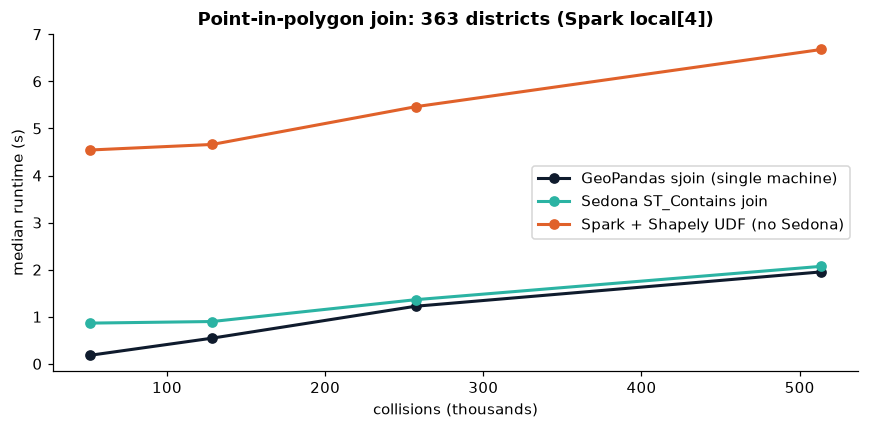

method,GeoPandas sjoin (single machine),Sedona ST_Contains join,Spark + Shapely UDF (no Sedona)
records,,,
51131,0.18,0.87,4.54
128588,0.55,0.90,4.66
257151,1.22,1.36,5.46
513748,1.95,2.07,6.68


In [37]:
# Free memory before the benchmark: drop every cached Spark table, keep only what is still needed
sedona.catalog.clearCache()
gb = sedona.read.format("geoparquet").load(str(WRANGLED_PATH))
lad_sdf.persist(StorageLevel.MEMORY_AND_DISK).createOrReplaceTempView("lad")
import gc; del pdf, tr, te; gc.collect()

from pyspark.sql.functions import pandas_udf
import shapely

lad_wkb = sedona.sparkContext.broadcast((list(lad_bng.geometry.to_wkb()), list(lad_bng.lad_code)))

@pandas_udf("string")
def pip_lookup(x: pd.Series, y: pd.Series) -> pd.Series:
    geoms_wkb, codes = lad_wkb.value
    polys = shapely.from_wkb(geoms_wkb)
    tree = shapely.STRtree(polys)
    pts = shapely.points(x.values, y.values)
    pt_idx, poly_idx = tree.query(pts, predicate="within")
    out = np.full(len(pts), None, dtype=object)
    out[pt_idx] = np.asarray(codes, dtype=object)[poly_idx]
    return pd.Series(out)

sedona.conf.set("spark.sql.execution.arrow.maxRecordsPerBatch", "100000")
lad_gp = lad_bng[["lad_code", "geometry"]]
bench = []
for frac in [0.1, 0.25, 0.5, 1.0]:
    sub = stored.sample(frac, seed=SEED) if frac < 1 else stored
    sub = sub.select("collision_index", "geom_bng", F.expr("ST_X(geom_bng)").alias("x"),
                     F.expr("ST_Y(geom_bng)").alias("y")).persist(StorageLevel.MEMORY_AND_DISK)
    n = sub.count(); sub.createOrReplaceTempView("bench_pts")
    sub_pd = sub.select("x", "y").toPandas()
    timings = {"Sedona ST_Contains join": [], "Spark + Shapely UDF (no Sedona)": [], "GeoPandas sjoin (single machine)": []}
    for rep in range(3):
        t0 = time.time()
        sedona.sql("SELECT /*+ BROADCAST(l) */ count(*) FROM bench_pts p JOIN lad l ON ST_Contains(l.lad_geom, p.geom_bng)").collect()
        timings["Sedona ST_Contains join"].append(time.time() - t0)
        t0 = time.time()
        sub.select(pip_lookup("x", "y").alias("c")).filter("c IS NOT NULL").count()
        timings["Spark + Shapely UDF (no Sedona)"].append(time.time() - t0)
        t0 = time.time()
        gpts = gpd.GeoDataFrame(geometry=gpd.points_from_xy(sub_pd.x, sub_pd.y), crs=27700)
        len(gpd.sjoin(gpts, lad_gp, predicate="within", how="inner"))
        timings["GeoPandas sjoin (single machine)"].append(time.time() - t0)
    for method, ts in timings.items():
        bench.append({"records": n, "method": method, "median_seconds": float(np.median(ts))})
    sub.unpersist()
bench = pd.DataFrame(bench)
bench_w = bench.pivot(index="records", columns="method", values="median_seconds")
fig, ax = plt.subplots(figsize=(8, 4))
for (method, s), c in zip(bench_w.items(), [NAVY, TEAL, ORANGE]):
    ax.plot(s.index / 1000, s.values, marker="o", label=method, color=c, lw=2)
ax.set_xlabel("collisions (thousands)"); ax.set_ylabel("median runtime (s)")
ax.set_title(f"Point-in-polygon join: 363 districts (Spark {sedona.sparkContext.master})"); ax.legend()
savefig("benchmark_spark_vs_sedona")
bench.to_csv(DOCS / "benchmark_spatial_join.csv", index=False)
bench_w.round(2)

**Interpretation.** Sedona's indexed spatial join is about **3× faster than the hand-written Spark UDF** at every size: the UDF pays Python serialisation and rebuilds a spatial index per batch. **GeoPandas is slightly faster than Sedona** at these sizes (≤ 0.5 M points), because everything fits in one machine's memory and there is no distributed scheduling overhead. The gap narrows as data grows, from 4.8× at 51k points to 1.06× at 514k. Sedona's value is that the same SQL scales out unchanged to a cluster and to data that does not fit in memory (for example the 7 M-row US Accidents dataset from the proposal), where GeoPandas cannot follow. This benchmark ran in Spark `local` mode on one laptop, so it does not measure multi-node scaling.

## 11. Step 5 – Deliver: exports for the interactive dashboard
The Streamlit dashboard (`app.py`) reads only the compact files in `data/dashboard/`, so it runs on Streamlit
Community Cloud without Spark:

| File | Content | Used for |
|---|---|---|
| `collisions_points.parquet` | every study collision: lon/lat, time, conditions, district, cluster ids | heatmap, filters, linked charts |
| `districts.geojson` + `district_stats.parquet` | simplified boundaries, fatal/KSI counts and rates, predicted risk | "which area is fatal", risk map |
| `grid_cells.parquet` | 5 km cells: temporal category, Gi* z / p / class | hotspot layers |
| `h3_risk.parquet` | H3 hexagons: predicted vs observed severity (2025) | risk hexagon map |
| `kmeans_clusters.parquet`, `dbscan_*_clusters.parquet` | cluster centres, hulls, sizes | cluster layers with popups |
| `association_rules.parquet` | severity rules | rule explorer |
| `severity_predictor.joblib`, `predictor_metadata.json` | deployable model + UI options | severity predictor |
| `model_metrics.json`, `project_summary.json` | evaluation tables, headline numbers | model tab, KPI cards |

In [38]:
pts = (gb.select("collision_index",
               F.round("longitude", 5).alias("lon"), F.round("latitude", 5).alias("lat"),
               F.col("collision_severity").alias("severity_code"), "severity", F.col("collision_year").alias("year"),
               "month", "hour", "day_of_week", "season", "time_band", "is_weekend", "speed_limit",
               F.col("weather_conditions_label").alias("weather"), F.col("light_conditions_label").alias("light"),
               F.col("road_surface_conditions_label").alias("surface"), F.col("road_type_label").alias("road_type"),
               F.col("first_road_class_label").alias("road_class"), F.col("junction_detail_label").alias("junction"),
               F.col("junction_control_label").alias("junction_control"), F.col("urban_or_rural_area_label").alias("area_type"),
               "lad_code", "lad_name", "h3_cell", "grid_id")
       .toPandas())
pts = (pts.merge(km_assign_pd, on="collision_index", how="left")
          .merge(fatal_db.rename(columns={"cluster": "dbscan_fatal_cluster"}), on="collision_index", how="left")
          .merge(ksi_db.rename(columns={"cluster": "dbscan_ksi_cluster"}), on="collision_index", how="left"))
pts[["kmeans_cluster", "dbscan_fatal_cluster", "dbscan_ksi_cluster"]] = \
    pts[["kmeans_cluster", "dbscan_fatal_cluster", "dbscan_ksi_cluster"]].fillna(-1)
for c in ["severity", "season", "time_band", "weather", "light", "surface", "road_type", "road_class", "junction",
          "junction_control", "area_type", "lad_code", "lad_name", "h3_cell", "grid_id"]:
    pts[c] = pts[c].astype("category")
for c in ["severity_code", "month", "hour", "day_of_week", "is_weekend", "speed_limit"]:
    pts[c] = pts[c].astype("int8")
pts["year"] = pts.year.astype("int16")
for c in ["kmeans_cluster", "dbscan_fatal_cluster", "dbscan_ksi_cluster"]:
    pts[c] = pts[c].astype("int32")
pts[["lon", "lat"]] = pts[["lon", "lat"]].astype("float32")
pts.drop(columns="collision_index").to_parquet(DASH / "collisions_points.parquet", compression="zstd", index=False)

# Districts: simplified boundaries + statistics + predicted risk
lad_web = lad_bng.copy(); lad_web["geometry"] = lad_web.geometry.simplify(250, preserve_topology=True)
lad_web = lad_web.to_crs(4326)
lad_web.to_file(DASH / "districts.geojson", driver="GeoJSON", COORDINATE_PRECISION=4)
district_stats = lad_stats.merge(lad_risk[["lad_code", "test_collisions", "mean_p_ksi", "risk_index", "observed_ksi_rate_2025"]],
                                 on="lad_code", how="left")
district_stats.to_parquet(DASH / "district_stats.parquet", index=False)

# 5 km grid cells with polygon corners in lon/lat
to_wgs = Transformer.from_crs(27700, 4326, always_xy=True)
def cell_polygon(gx, gy):
    xs = np.array([gx, gx + 1, gx + 1, gx, gx]) * GRID_M; ys = np.array([gy, gy, gy + 1, gy + 1, gy]) * GRID_M
    lon, lat = to_wgs.transform(xs, ys)
    return [[round(a, 5), round(b, 5)] for a, b in zip(lon, lat)]
grid_out = grid.copy()
grid_out["polygon"] = [json.dumps(cell_polygon(x, y)) for x, y in zip(grid_out.grid_x, grid_out.grid_y)]
grid_out["lon"], grid_out["lat"] = to_wgs.transform((grid_out.grid_x + 0.5).values * GRID_M, (grid_out.grid_y + 0.5).values * GRID_M)
grid_out.to_parquet(DASH / "grid_cells.parquet", index=False)

h3_risk.to_parquet(DASH / "h3_risk.parquet", index=False)
km_out = km_profile.copy()
km_out["lon"], km_out["lat"] = to_wgs.transform(km_out.easting.values, km_out.northing.values)
km_out.drop(columns=["easting", "northing"]).to_parquet(DASH / "kmeans_clusters.parquet", index=False)
fatal_clusters.to_parquet(DASH / "dbscan_fatal_clusters.parquet", index=False)
ksi_clusters.to_parquet(DASH / "dbscan_ksi_clusters.parquet", index=False)
rules.drop(columns=["consequent"]).to_parquet(DASH / "association_rules.parquet", index=False)

model_metrics = {
    "multiclass": comparison_all.round(4).to_dict(orient="records"),
    "binary_ksi": binary.round(4).to_dict(orient="records"),
    "confusion_matrices": {k: v.tolist() for k, v in confusions.items()},
    "rf_feature_importance": imp.sort_values(ascending=False).round(4).to_dict(),
    "lad_risk_spearman": round(float(rho), 3), "class_names": CLASS_NAMES, "test_year": TEST_YEAR,
    "kmeans_scan": km_scan.round(4).to_dict(orient="records"), "kmeans_k": K_BEST,
    "benchmark": bench.round(3).to_dict(orient="records"),
}
jdump(model_metrics, DASH / "model_metrics.json")

summary = {
    "raw_records": int(n_raw), "study_records": int(n_gb), "missing_coordinates": int(quality["missing_coordinates"]),
    "outside_gb": int(quality["outside_great_britain"]), "years": f"{min(years)}–{max(years)}",
    "fatal": int((pts.severity_code == 1).sum()), "serious": int((pts.severity_code == 2).sum()),
    "slight": int((pts.severity_code == 3).sum()), "districts": int(len(lad_stats)),
    "occupied_cells": int(len(grid)), "grid_threshold": float(threshold),
    "persistent_cells": int((grid.temporal_category == "Persistent").sum()),
    "gi_hot_99": int((grid.gi_class == "Hot spot (99%)").sum()), "gi_hot_95": int((grid.gi_class == "Hot spot (95%)").sum()),
    "kmeans_k": K_BEST, "dbscan_fatal_clusters": int(len(fatal_clusters)), "dbscan_ksi_clusters": int(len(ksi_clusters)),
    "dbscan_params": {"fatal": DBSCAN_FATAL, "ksi": DBSCAN_KSI},
    "fp_itemsets": int(n_itemsets), "severity_rules": int(len(rules)), "fp_min_support": FP_MIN_SUPPORT,
    "rf_macro_f1": float(comparison.set_index("Model").loc["Class-Weighted Random Forest", "Macro F1"]),
    "postgis": postgis_result, "spark_version": sedona.version, "sedona_version": sedona_pkg.version,
}
jdump(summary, DASH / "project_summary.json")
jdump(quality, DOCS / "data_quality_summary.json")
pd.DataFrame([(f.name, round(f.stat().st_size / 1e6, 2)) for f in sorted(DASH.iterdir())], columns=["file", "MB"])

,file,MB
0,association_rules.parquet,0.49
1,collisions_points.parquet,9.43
2,dbscan_fatal_clusters.parquet,0.13
3,dbscan_ksi_clusters.parquet,0.21
4,district_stats.parquet,0.05
5,districts.geojson,1.63
6,grid_cells.parquet,0.60
7,h3_risk.parquet,0.50
8,kmeans_clusters.parquet,0.01
9,model_metrics.json,0.00


## 12. Conclusions, limitations and reproducibility

In [39]:
print(json.dumps({k: v for k, v in summary.items() if k not in ("postgis", "dbscan_params")}, indent=1, default=str))

{
 "raw_records": 513801,
 "study_records": 513745,
 "missing_coordinates": 53,
 "outside_gb": 3,
 "years": "2021\u20132025",
 "fatal": 7552,
 "serious": 116796,
 "slight": 389397,
 "districts": 363,
 "occupied_cells": 7617,
 "grid_threshold": 64.0,
 "persistent_cells": 257,
 "gi_hot_99": 278,
 "gi_hot_95": 83,
 "kmeans_k": 15,
 "dbscan_fatal_clusters": 114,
 "dbscan_ksi_clusters": 186,
 "fp_itemsets": 468190,
 "severity_rules": 11649,
 "fp_min_support": 0.002,
 "rf_macro_f1": 0.3460989241419427,
 "spark_version": "3.5.3",
 "sedona_version": "1.7.1"
}


### Answers to the research questions

**RQ1 – Where do (severe) collisions concentrate?**
* Grid screening (95th percentile = 64 collisions per 5 km cell-year) flags **257 persistent cells**, high-count in all five years, plus 34 emerging, 27 declining and 68 variable cells.
* **Getis-Ord Gi\*** confirms **278 statistically significant KSI hot-spot cells at 99 % and 83 at 95 %** (FDR-corrected), concentrated in Greater London, Birmingham/West Midlands, Greater Manchester, West Yorkshire and Glasgow. There are no significant cold spots, because cells without any collision are not part of the grid.
* **K-Means (k = 15, elbow)** divides severe crashes into regional zones dominated by the London, Manchester and Leeds–Sheffield conurbations.
* **Sedona DBSCAN** finds **114 local clusters of fatal collisions** (≥ 4 fatal crashes chained within 1 km) and **186 junction-scale KSI clusters** (≥ 12 within 150 m); only 8 % of fatal and 3 % of KSI crashes fall in a dense cluster, so most severe crashes are dispersed along the network.
* *Counts* are highest in cities (Birmingham has the most fatal collisions), but the *fatality rate* is highest in rural districts: Aberdeenshire (78 fatal per 1,000 collisions), Highland (71), Gwynedd (58), against a GB average of 14.7.

**RQ2 – When do collisions happen?** Volume peaks in weekday afternoon commuting (15:00–18:00). Severity peaks at **night and at weekends**, when there are fewer crashes but a larger share are KSI. Yearly totals are roughly flat (101–106k), but the **KSI share rose from 22.5 % in 2021 to 26.2 % in 2025**. Night-time collisions (00–05) are KSI in 30.5 % of cases, against 23.7 % in the daytime.

**RQ3 – Which conditions go with severe outcomes?** FP-Growth (468k frequent itemsets, 11,649 severity rules) finds that fatal outcomes are **3.4–3.9× more likely than average** for *rural + not at a junction + darkness without street lighting* and for *A-road + single carriageway + 60 mph*. Serious outcomes are over-represented on **60 mph roads at weekends**, especially B-roads in summer. Rain is *not* associated with higher severity (KSI 24.0 % vs 24.7 % in fine weather), probably because traffic is slower; wet surfaces are only slightly worse (25.4 % vs 24.3 %), while **high winds** are clearly worse (KSI 27–30 %).

**RQ4 – How well can severity be predicted, and where is predicted risk highest?** On the unseen 2025 data the class-weighted Random Forest reaches **macro F1 = 0.346** and finds **55 % of fatal** collisions (the unweighted baseline finds 0 %). Fatal precision is only ~4 %, and the binary GBT reaches ROC AUC 0.62. Severity is only partly predictable from scene conditions. Aggregated to districts, the model's **predicted risk index ranks areas well (Spearman ρ = 0.66 with the observed 2025 KSI share)**. It is highest in the Highlands, Aberdeenshire, Dumfries & Galloway and rural Wales, and lowest in inner London.

### Spark vs Sedona
On one machine with 0.5 M points, Sedona's spatial join is **about 3× faster than a hand-written Spark UDF** for the same task, and close to GeoPandas (2.1 s vs 2.0 s). GeoPandas wins at this small size because it has no distributed overhead. Sedona's advantage is that the same SQL scales to a cluster and to datasets that do not fit in memory.

### Limitations
* **No exposure data:** counts and hotspots reflect traffic volume as well as danger; rates per vehicle-km would need traffic counts.
* **Severity recording differs by police force** (CRASH system). `police_force` is a top predictor partly for this reason. DfT's adjusted-severity fields could be used for a sensitivity analysis.
* Some predictors (light, weather, surface) are recorded at the scene after the crash, so the model is not a validated *pre-crash* predictor.
* Hotspot results depend on grid size, Gi\* neighbourhood and DBSCAN parameters (all set in §1); results for other settings are not shown.
* PostGIS storage runs only when a PostGIS server is reachable (§4.4); otherwise GeoParquet is the store.
* Association rules show co-occurrence, not causation.

### Reproducibility
Raw data download automatically from DfT/ONS (§1). All parameters are in one cell, the random seed is 42, and the chronological test year is 2025. The notebook ran end-to-end with Spark 3.5.3 and Sedona 1.7.1 in `local[4]` mode on a laptop. The same code runs on the DGX by setting `SPARK_MASTER`.

In [40]:
sedona.stop()